<a href="https://colab.research.google.com/github/kishoreakaveeti/Projects/blob/main/PaperWalkthroughs/Toy_Models_of_Superposition_From_First_Principles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Toy Models of Superposition — from first principles to research literacy
## A hands-on companion to Elhage et al. (2022)

**For Kishore:** you know a little Python and have met neural networks. That is enough to start. We will build every piece of mathematics we use, inspect actual numbers, train small networks, and return to the research questions with considerably sharper tools.

**The central puzzle:** how can a network with only two hidden numbers represent five useful features? The answer is neither magic nor a violation of linear algebra. It involves the distribution of inputs, a willingness to tolerate errors, and a nonlinear filter.

This is an original educational companion, not a reproduction of the paper's prose. Read it alongside the [original interactive article](https://transformer-circuits.pub/2022/toy_model/index.html) or [62-page PDF](https://transformer-circuits.pub/2022/toy_model/toy_model.pdf). The main text was published **14 September 2022**. Later comments on the live page are distinguished from the original results.

### What “zero to hero” means here

By the end you should be able to derive the main reconstruction equations, explain why sparsity changes the trade-off, implement and debug the model, read its weight geometry, distinguish the paper's different architectures, and critically assess what does and does not follow for LLMs. No single notebook can establish mastery of every cited field or reproduce every research sweep. We cover every major section, with deeper derivations for the central mechanism and guided extensions for the more expensive experiments.

**How to use this notebook:** read in order the first time. Run every cell from the top. Predict outputs before revealing them. A plot is evidence about the code and configuration that produced it; it is not automatically a reproduction of a published figure.

**Runtime:** Python 3.10+, NumPy, Matplotlib. No GPU, API keys, model downloads, or PyTorch required. All experiments were executed in this notebook. Training time depends on your CPU; the default small experiments are intended for an ordinary laptop. Rerunning replaces in-memory results only.


## Reading map

| Part | You will learn | Corresponding paper material |
|---|---|---|
| 1. Vocabulary and mathematics | Features, neurons, vectors, dot products, matrices, probability, loss | Background and definitions |
| 2. A complete numerical model | Encoding, decoding, interference, ReLU, bias | Demonstrating superposition |
| 3. Why it works | Sparse events, exact examples, linear baseline | Mathematical understanding |
| 4. Train it yourself | Gradients, tied weights, Adam, diagnostics | Experimental setup and basic results |
| 5. Phase changes | Analytic candidate strategies and a phase diagram | Superposition as a phase change |
| 6. Geometry | Antipodes, polygons, tetrahedra, fractional dimensionality | Geometry of superposition |
| 7. Beyond independent features | Co-occurrence, local bases, training trajectories | Non-uniform superposition and learning dynamics |
| 8. Robustness and basis | Attacks, rotations, neuron interpretation | Adversarial examples and privileged bases |
| 9. Computation | Absolute value, untied weights, asymmetric interference | Computation in superposition |
| 10. Research perspective | Sparse recovery, SAEs, limitations, section guide | Strategy, discussion, related work, appendices |

Suggested pace: 6–10 sittings of 45–90 minutes, with additional time for exercises. The aim is understanding, not winning a speed-reading competition with a matrix.


In [ ]:
import sys, time, math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42
rng = np.random.default_rng(SEED)

def relu(z):
    """Return z when z is positive, otherwise zero; works on arrays."""
    return np.maximum(z, 0.0)

def describe(name, a):
    a = np.asarray(a)
    print(f'{name}, shape={a.shape}:\n{a}\n')


Python: 3.12.14
NumPy: 2.3.5
Matplotlib: 3.10.8


# Part 1 — build the language before using it
## 1. Features are questions; activations are their answers

Imagine a tiny image recognizer with five questions: “red?”, “curved?”, “furry?”, “has wheels?”, “contains text?” A **feature** is an independently useful property. A **feature activation** is the strength with which that property is present in one example. A **neuron** is a particular coordinate in a network's hidden activation array. They are different kinds of things: one concerns what information means, the other concerns where a number sits.

A neuron might activate for both wheels and curved letters. That is a candidate example of **polysemanticity**: several meanings share a neuron. A neuron associated with one interpretable property is called **monosemantic**. Real interpretations depend on the data and interventions; a label attached after looking at five examples is not a proof.

In this toy world we deliberately know the true features: they are coordinates of the synthetic input. That is the experimental superpower. In an LLM we do not start with a complete list of the true features, their meanings, or their activations.

Three distinctions to keep beside your keyboard:

| Term | Meaning | Common confusion |
|---|---|---|
| Weight | A learned parameter, fixed during ordinary inference | Not the current presence of a concept |
| Activation | A value computed for the current input | Not a permanent entry in a fact table |
| Feature direction | A pattern across activation coordinates that encodes a property | Not necessarily one neuron |
| Superposition | More represented feature directions than available dimensions | Not merely using several neurons for one feature |
| Sparse activation | Few candidate features present on a typical example | Not necessarily many zero weights |

The paper concerns representations, not a direct map from individual factual memories to individual weight entries. “Where is the Eiffel Tower fact?” is a different, harder question than “which activation direction encodes this known synthetic feature?”


## 2. Scalars, vectors, dimensions, and basis directions

A **scalar** is one number, such as $0.8$. A **vector** is an ordered list of numbers. We write a five-feature input as a column:

$$
x=\begin{bmatrix}0.8\\0\\0.3\\0\\0\end{bmatrix}\in\mathbb{R}^{5}.
$$

The symbol $\mathbb{R}$ means the real numbers; the superscript 5 means five coordinates, not “raise every number to the fifth power.” The index $x_i$ means entry $i$. In equations we normally start at 1; Python starts at 0.

A **dimension** is an independent coordinate you can vary. In a two-dimensional hidden space we have $h=[h_1,h_2]^\top$. The two standard **basis vectors** are $e_1=[1,0]^\top$ and $e_2=[0,1]^\top$. They are the horizontal and vertical rulers. Every point can be written $h=h_1e_1+h_2e_2$.

There are infinitely many directions on a sheet of paper, but only two independent dimensions. This is the first clue: five arrows can point in five different directions in 2D. The hard part is telling which combination of arrows produced an observed point.

**Distributed representation** means a feature can involve multiple coordinates. Three orthogonal feature directions rotated across three neurons are distributed without being overcomplete. Superposition requires the additional capacity tension: more represented features than independent dimensions.


In [ ]:
x = np.array([0.8, 0.0, 0.3, 0.0, 0.0])
describe('x', x)
print('First coordinate in Python:', x[0])
print('Nonzero feature count:', np.count_nonzero(x))
print('Two-dimensional basis:', np.eye(2), sep='\n')


x, shape=(5,):
[0.8 0.  0.3 0.  0. ]

First coordinate in Python: 0.8
Nonzero feature count: 2
Two-dimensional basis:
[[1. 0.]
 [0. 1.]]


## 3. Length, dot products, and angles

The Euclidean length, also called the **$L_2$ norm**, is

$$\|v\|_2=\sqrt{v_1^2+v_2^2+\cdots+v_m^2}.$$

For $v=[3,4]^\top$, length is $\sqrt{9+16}=5$. A **unit vector** has length 1. Normalizing $v$ means dividing by its length: $\hat v=v/\|v\|_2$, provided $v\ne0$.

The **dot product** multiplies corresponding entries and adds them:

$$u\cdot v=u^\top v=\sum_{k=1}^{m}u_kv_k=\|u\|_2\|v\|_2\cos\theta.$$

The capital-sigma-looking symbol $\sum$ means “add these terms.” The superscript $\top$ means transpose: turn a column into a row, or swap matrix rows and columns. The angle formula tells us that equal directions have a positive dot product, perpendicular directions have zero, and opposite directions have a negative dot product.

**Orthogonal** means perpendicular. **Antipodal** means pointing in exactly opposite directions. Antipodal vectors are maximally overlapping with a negative sign; they are not orthogonal. Later that negative sign will be useful because ReLU deletes negative outputs.

For unit vectors, $u\cdot v=\cos\theta$. Without normalization, the dot product also depends on lengths. A large dot product can mean alignment, large norms, or both.


same dot = 1.0 length = 1.0
perpendicular dot = 0.0 length = 1.0
opposite dot = -1.0 length = 1.0
diagonal dot = 1.0 length = 1.4142135623730951


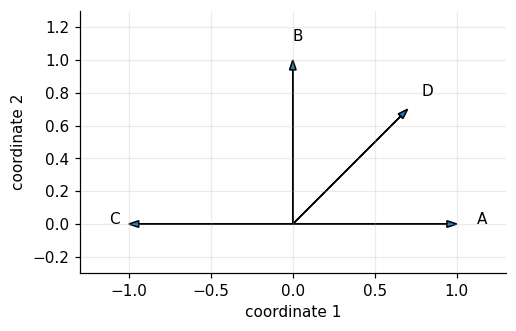

In [ ]:
u = np.array([1., 0.])
for label, v in [('same', [1,0]), ('perpendicular', [0,1]),
                 ('opposite', [-1,0]), ('diagonal', [1,1])]:
    v = np.array(v, dtype=float)
    print(label, 'dot =', u @ v, 'length =', np.linalg.norm(v))

fig, ax = plt.subplots(figsize=(5,4))
for label, v in [('A', [1,0]), ('B', [0,1]), ('C', [-1,0]), ('D', [.7,.7])]:
    ax.arrow(0,0,*v, head_width=.04, length_includes_head=True)
    ax.text(v[0]*1.12,v[1]*1.12,label)
ax.set(xlim=(-1.3,1.3), ylim=(-.3,1.3), xlabel='coordinate 1', ylabel='coordinate 2')
ax.set_aspect('equal'); ax.grid(alpha=.25)
plt.show()


## 4. Matrices are machines for mixing coordinates

A matrix is a rectangular table of numbers. Its **shape** is rows × columns. Our encoder has $m=2$ hidden coordinates and $n=5$ input features, so

$$W\in\mathbb{R}^{m\times n}=\mathbb{R}^{2\times5},\qquad h=Wx.$$

To compute hidden coordinate $h_a$, multiply row $a$ of $W$ by the input and add:

$$h_a=\sum_{i=1}^{n}W_{ai}x_i.$$

An equivalent, much more revealing view is

$$h=\sum_{i=1}^{n}x_iw_i,$$

where $w_i=W_{:,i}$ is the **$i$th column** of $W$. Each column is a feature's arrow in hidden space. The input activation scales that arrow, then all scaled arrows add. Column 3 is where feature 3 goes when it is the only active feature.

Python's `@` is matrix multiplication. `*` usually means element-by-element multiplication in NumPy. Mixing these up can produce plausible-looking nonsense, the most dangerous variety of nonsense.

The **rank** of a matrix counts independent directions in its output. A $2\times5$ matrix has rank at most 2. No decoder can uniquely recover every possible five-dimensional input from this linear encoder. We will never claim otherwise.


In [ ]:
W_example = np.array([[1., 0., -1.,  0.6, -0.6],
                      [0., 1.,  0.,  0.8, -0.8]])
h = W_example @ x
describe('W', W_example)
describe('h = W @ x', h)
describe('sum of scaled columns', (W_example * x[None, :]).sum(axis=1))
assert np.allclose(h, (W_example * x[None,:]).sum(axis=1))
print('Rank:', np.linalg.matrix_rank(W_example))


W, shape=(2, 5):
[[ 1.   0.  -1.   0.6 -0.6]
 [ 0.   1.   0.   0.8 -0.8]]

h = W @ x, shape=(2,):
[0.5 0. ]

sum of scaled columns, shape=(2,):
[0.5 0. ]

Rank: 2


## 5. Probability without a statistics prerequisite

Probability describes how often something happens under a specified random process. An **expectation** is its probability-weighted average. If a fair coin pays 0 or 2, the expected payment is $\tfrac12\cdot0+\tfrac12\cdot2=1$, even though no individual payment is 1.

We generate one feature by flipping an “active?” coin, then choosing a strength if it is active:

$$
z_i\sim\operatorname{Bernoulli}(p_i),\qquad
u_i\sim\operatorname{Uniform}(0,1),\qquad x_i=z_i u_i.
$$

The symbol $\sim$ means “is sampled from.” A Bernoulli variable is 1 with probability $p_i$, otherwise 0. Uniform means all equal-length subintervals are equally likely. In the paper, $S_i$ is the probability of zero. We use $p_i=1-S_i$, the **probability of being active**, because it is easier to keep the direction straight. **Smaller $p$ means sparser features.**

For independent features, the active coins are independent. Therefore two specific features co-occur with probability $p^2$; at $p=0.01$, each appears about once per hundred examples but the pair appears about once per ten thousand.

Do not confuse independence with mutual exclusion. Independent features can co-occur. Mutually exclusive features cannot.


In [ ]:
def sample_data(rng, batch, n, p, signed=False):
    """Rows are examples, columns are known synthetic features."""
    p = np.broadcast_to(np.asarray(p, dtype=float), (n,))
    if np.any((p < 0) | (p > 1)):
        raise ValueError('Activation probabilities must lie in [0,1].')
    active = rng.random((batch,n)) < p
    values = rng.uniform(-1,1,(batch,n)) if signed else rng.random((batch,n))
    return active * values

X_demo = sample_data(np.random.default_rng(1), 100_000, 5, .05)
print('Observed activation frequencies:', (X_demo != 0).mean(axis=0))
print('Observed co-occurrence, features 0 and 1:',
      np.mean((X_demo[:,0] != 0) & (X_demo[:,1] != 0)))
print('Expected pair frequency:', .05**2)
print('Mean active count per example:', (X_demo != 0).sum(axis=1).mean())


Observed activation frequencies: [0.051 0.05  0.05  0.05  0.051]
Observed co-occurrence, features 0 and 1: 0.00287
Expected pair frequency: 0.0025000000000000005
Mean active count per example: 0.25149


## 6. Loss: what does “useful” mean to this network?

A model needs a numerical objective. For one input and reconstruction, define

$$\ell(x,\hat x)=\sum_{i=1}^{n}I_i(\hat x_i-x_i)^2.$$

The importance $I_i>0$ says how expensive errors on feature $i$ are. If $I_1=10$ and $I_2=1$, equal-sized mistakes on feature 1 cost ten times as much. Importance is supplied by us; it is not an attention score or a model's personal opinion.

The population loss is the average over the data-generating process:

$$\mathcal L=\mathbb E_x[\ell(x,\hat x)].$$

We approximate it with $B$ random examples:

$$\hat{\mathcal L}=\frac1B\sum_{r=1}^{B}\sum_{i=1}^{n}I_i(\hat x_{ri}-x_{ri})^2.$$

Here $r$ indexes rows/examples. Our code averages over examples and **sums over features**. Some libraries average over both, giving a factor of $1/n$. Either convention can work, but gradients and learning rates must match.

Two errors matter: **false positives**, predicting a feature when it is absent, and **false negatives/distortion**, missing or changing a feature that is present. Sparse training makes zeros common, so a zero predictor can obtain a deceptively small average loss. We will therefore also evaluate active-feature error and single-feature probes.


In [ ]:
def weighted_mse(pred, target, importance):
    return np.mean(np.sum(np.asarray(importance) * (pred-target)**2, axis=1))

target = np.array([[1.,0.]])
pred = np.array([[.7,.2]])
print('Errors squared:', (pred-target)**2)
print('Weighted loss:', weighted_mse(pred,target,np.array([10.,1.])))


Errors squared: [[0.09 0.04]]
Weighted loss: 0.9400000000000003


# Part 2 — inspect the mechanism with actual numbers
## 7. Encoder, decoder, and the smallest nonlinear filter

The central model is

$$h=Wx,\qquad a=W^\top h+b,\qquad\hat x=\operatorname{ReLU}(a).$$

ReLU means **rectified linear unit** and acts separately on each entry:

$$\operatorname{ReLU}(t)=\max(0,t).$$

The bias $b\in\mathbb R^n$ is an adjustable offset, one per output. Combining the equations gives

$$\boxed{\hat x=\operatorname{ReLU}(W^\top Wx+b).}$$

The decoder uses the transpose of the encoder's weights. This is called **weight tying**. It does not mean $W^\top$ is an inverse. A rectangular matrix cannot invert the information it discarded. Tying makes the geometry easy to inspect and reduces the parameter count.

Shape audit: $W$ is $m\times n$, $x$ is $n\times1$, $h$ is $m\times1$, $W^\top h$ is $n\times1$, and so is $b$. Shapes are the unit tests of algebra.

Our batch code uses **rows as examples**. The same calculation becomes `H = X @ W.T`, `A = H @ W + b`, `Y = relu$A$`. Nothing about the mathematics changed; the array orientation did.


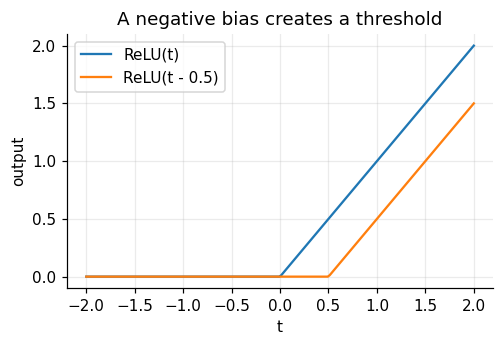

In [ ]:
grid = np.linspace(-2,2,200)
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(grid,relu(grid),label='ReLU(t)')
ax.plot(grid,relu(grid-.5),label='ReLU(t - 0.5)')
ax.set(xlabel='t',ylabel='output',title='A negative bias creates a threshold')
ax.legend(); ax.grid(alpha=.25); plt.show()


## 8. Two features, one hidden number: the entire trick on a napkin

Choose $W=[1,-1]$ and $b=0$. Then

$$h=x_1-x_2,\qquad\hat x_1=\max(0,h),\quad\hat x_2=\max(0,-h).$$

If $x=[0.8,0]^\top$, then $h=0.8$, so reconstruction is $[0.8,0]^\top$. If $x=[0,0.6]^\top$, then $h=-0.6$, so reconstruction is $[0,0.6]^\top$. We recover **either feature perfectly when it appears alone**.

But if $x=[0.8,0.6]^\top$, then $h=0.2$, giving $[0.2,0]^\top$. Both features lose 0.6. And $[0.7,0.7]^\top$ collides with the all-zero input: both encode as $h=0$.

There is no universal recovery. The strategy bets on a distribution where the collision-prone combinations are rare. A dimension is being time-shared statistically, with the sign helping separate two alternatives.

If the two features were mutually exclusive, this same construction would be exact on the entire supported input distribution. For independent sparse features it is approximate because co-occurrence remains possible.


In [ ]:
W_pair = np.array([[1.,-1.]])
X_pair = np.array([[.8,0],[0,.6],[.8,.6],[.7,.7],[0,0]])
H_pair = X_pair @ W_pair.T
Y_pair = relu(H_pair @ W_pair)
for xx,hh,yy in zip(X_pair,H_pair,Y_pair):
    print('input',xx, 'hidden',hh, 'prediction',yy)
assert np.allclose(Y_pair[:2], X_pair[:2])
assert np.allclose(H_pair[-2],H_pair[-1])


input [0.8 0. ] hidden [0.8] prediction [0.8 0. ]
input [0.  0.6] hidden [-0.6] prediction [0.  0.6]
input [0.8 0.6] hidden [0.2] prediction [0.2 0. ]
input [0.7 0.7] hidden [0.] prediction [0. 0.]
input [0. 0.] hidden [0.] prediction [0. 0.]


## 9. The Gram matrix is an interference map

Define the **Gram matrix** $G=W^\top W\in\mathbb R^{n\times n}$. Entry $G_{ij}=w_i\cdot w_j$ compares two feature arrows. This gives a coordinate-by-coordinate explanation:

$$a_i=G_{ii}x_i+\sum_{j\ne i}G_{ij}x_j+b_i.$$

Read the equation from left to right: self-signal, contributions from other active features, offset. On the diagonal $G_{ii}=\|w_i\|_2^2\ge0$. Off the diagonal, positive values can activate absent features; negative values can suppress outputs. With a single active feature, negative cross-talk at absent outputs is removed by ReLU. With multiple active features, the same negative cross-talk may suppress a genuine signal.

For our antipodal pair,

$$G=\begin{bmatrix}1&-1\\-1&1\end{bmatrix}.$$

The negative off-diagonal entries are harmless when their target feature is absent and harmful when both are present. **“Negative interference is free” needs the single-active-feature qualification.**

A represented feature has a non-negligible column $w_i$. But nonzero norm alone does not certify good recovery: a model can encode a feature weakly, or confuse it with others. Inspect norms, geometry, and conditional reconstruction together.


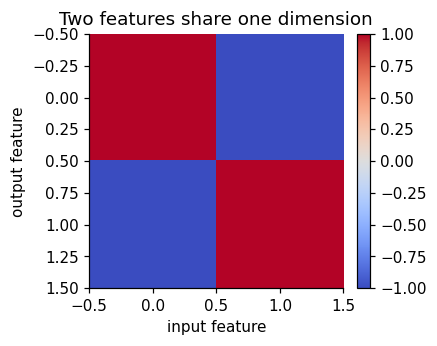

In [ ]:
def heatmap(ax, matrix, title, symmetric=True):
    vmax = max(float(np.max(np.abs(matrix))), 1e-6)
    im = ax.imshow(matrix, cmap='coolwarm' if symmetric else 'viridis',
                   vmin=-vmax if symmetric else 0, vmax=vmax)
    ax.set_title(title); ax.set_xlabel('input feature'); ax.set_ylabel('output feature')
    plt.colorbar(im,ax=ax,fraction=.046,pad=.04)

fig, ax = plt.subplots(figsize=(4,3))
heatmap(ax,W_pair.T @ W_pair,'Two features share one dimension')
plt.show()


## 10. Five feature directions inside two dimensions

A regular pentagon supplies five evenly spaced unit arrows. It is a teaching construction, not a guarantee that every trained five-feature model must learn a pentagon. Equal importance, sparsity, optimization, and biases all affect the result.

For angles $\theta_i=2\pi i/5$, use $w_i=[\cos\theta_i,\sin\theta_i]^\top$. Adjacent arrows have dot product $\cos72^\circ\approx0.309$; nonadjacent arrows have $\cos144^\circ\approx-0.809$.

An isolated feature of strength 1 activates its own output at 1 and creates two positive false positives of 0.309 before biasing. Its two negative cross-talk outputs are clipped to zero. A negative bias of -0.31 suppresses those false positives, but reduces its own recovered amplitude to 0.69. We trade cross-talk for shrinkage. Smaller true signals suffer more; a negative bias is a threshold, not a free noise eraser.

This is why the learned norms need not be exactly 1. The model can rescale weights and tune bias together to improve average error across the strengths that actually occur.


No bias: [[1.    0.309 0.    0.    0.309]]
Bias -0.31: [[0.69 0.   0.   0.   0.  ]]


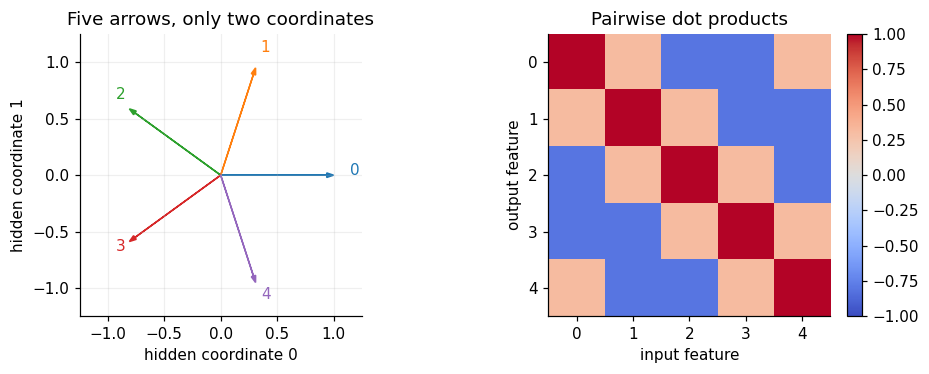

In [ ]:
def polygon_weights(k):
    angles = 2*np.pi*np.arange(k)/k
    return np.stack([np.cos(angles),np.sin(angles)])

def arrows(ax,W,title):
    colors = plt.cm.tab10(np.arange(W.shape[1])%10)
    for i, (v,c) in enumerate(zip(W.T,colors)):
        ax.arrow(0,0,*v,color=c,head_width=.04,length_includes_head=True)
        ax.text(*(1.15*v),str(i),color=c)
    lim=max(1.2,1.25*np.max(np.abs(W)))
    ax.set(xlim=(-lim,lim),ylim=(-lim,lim),title=title,
           xlabel='hidden coordinate 0',ylabel='hidden coordinate 1')
    ax.set_aspect('equal'); ax.grid(alpha=.2)

W5=polygon_weights(5)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
arrows(axs[0],W5,'Five arrows, only two coordinates')
heatmap(axs[1],W5.T@W5,'Pairwise dot products')
plt.tight_layout(); plt.show()
probe=np.eye(5)[[0]]
print('No bias:', relu(probe@W5.T@W5))
print('Bias -0.31:', relu(probe@W5.T@W5-.31))


# Part 3 — why sparsity makes the bargain attractive
## 11. The counting argument, including its hidden condition

Let $K$ be the number of active features among $n$ independent equal-probability features. It has a binomial distribution:

$$\Pr(K=k)=\binom nk p^k(1-p)^{n-k}.$$

The coefficient $\binom nk$, “$n$ choose $k$,” counts which $k$ features are active. The expectation is $\mathbb E[K]=np$. For $n=5,p=.02$, the average count is .1. Most inputs are zero; most nonzero inputs activate just one feature.

The population loss can be decomposed exactly:

$$\mathcal L=\sum_{k=0}^{n}\Pr(K=k)\,\mathbb E[\ell\mid K=k].$$

The vertical bar means “conditioned on.” For $k=1$, we also average over which feature is active and its strength. If $L_k$ denotes a *sum* over patterns rather than their conditional average, combinatorial coefficients move into its definition. This explains apparently different versions of the expansion.

The single-feature approximation is justified when **$np\ll1$** for the relevant collection of features, not merely when $p$ looks small. If $n=10{,}000,p=.001$, then $np=10$; many features are active despite each one being individually rare. In larger systems, sparsity of the interference neighbourhood can matter more than global one-feature sparsity.


p=0.8: P(0)=0.0003, P(1)=0.0064, P(2+)=0.9933
p=0.2: P(0)=0.3277, P(1)=0.4096, P(2+)=0.2627
p=0.02: P(0)=0.9039, P(1)=0.0922, P(2+)=0.0038


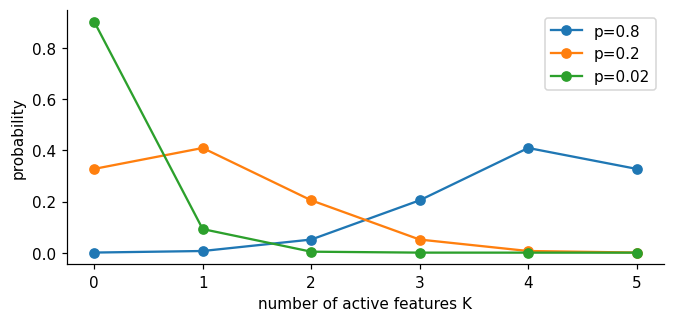

In [ ]:
def active_count_probs(n,p):
    return np.array([math.comb(n,k)*p**k*(1-p)**(n-k) for k in range(n+1)])

fig,ax=plt.subplots(figsize=(7,3))
for p in [.8,.2,.02]:
    probs=active_count_probs(5,p)
    ax.plot(np.arange(6),probs,'o-',label=f'p={p}')
    print(f'p={p}: P(0)={probs[0]:.4f}, P(1)={probs[1]:.4f}, P(2+)={probs[2:].sum():.4f}')
ax.set(xlabel='number of active features K',ylabel='probability',xticks=np.arange(6))
ax.legend(); plt.show()


## 12. Derive the one-active-feature loss

Suppose only feature $j$ is active, with strength $u\in[0,1]$. Then $x=ue_j$, where $e_j$ has a 1 at coordinate $j$ and zeros elsewhere. The pre-output is $a_i=G_{ij}u+b_i$. Therefore

$$
\ell(ue_j)=I_j\left(u-\operatorname{ReLU}(G_{jj}u+b_j)\right)^2
+\sum_{i\ne j}I_i\operatorname{ReLU}(G_{ij}u+b_i)^2.
$$

The first term measures self-reconstruction error. The second penalizes false positives at absent outputs. Notice the importance index in that sum is **$i$, the mistaken output**, not $j$, the source feature. A low-importance input feature is still expensive if it spuriously activates a high-importance output.

If $b=0$, the arrows have unit length, and $u\ge0$, self-error vanishes and

$$\ell(ue_j)=u^2\sum_{i\ne j}I_i[\max(0,G_{ij})]^2.$$

For a uniformly distributed strength, $\mathbb E[u^2]=1/3$. One way to see it is to average the curve $u^2$ from 0 to 1; the exact area is $\int_0^1u^2\,du=1/3$. We will numerically verify this instead of asking you to already know integration.

This isolates the geometric pressure: suppress positive overlaps. It does **not** solve the full training problem, because multiple-feature events and bias-dependent self-distortion also matter.


In [ ]:
u=np.random.default_rng(3).random(200_000)
print('Monte Carlo E[u^2]:',np.mean(u**2),'exact:',1/3)
G5=W5.T@W5
predicted_single_loss=(np.maximum(G5,0)**2).sum(axis=0)-1
print('Unit-strength isolated-feature loss, each source:',predicted_single_loss)


Monte Carlo E[u^2]: 0.33362195844818604 exact: 0.3333333333333333
Unit-strength isolated-feature loss, each source: [0.191 0.191 0.191 0.191 0.191]


## 13. Why a linear bottleneck behaves differently

Remove output ReLU and consider $\hat x=Gx+b$. A positive and a negative false output are both errors under squared loss. The negative half of the interference map no longer disappears.

For a clean derivation, take **centered, independent** features with mean zero and variances $v_i$. Centered means subtracting the mean. The expected weighted loss with zero bias is

$$
\mathcal L_{\rm lin}=\sum_{i=1}^{n}I_i\left[
v_i(1-G_{ii})^2+\sum_{j\ne i}v_jG_{ij}^2\right].
$$

Expand $x_i-\sum_jG_{ij}x_j$, square it, and average. Cross terms vanish because independent centered variables satisfy $\mathbb E[x_ix_j]=0$ for $i\ne j$. The remaining terms are the diagonal benefit and squared interference cost.

For equally distributed independent features with different importances, keeping the $m$ most important coordinates is an optimal linear solution. With equal importances, there are degenerate optimal subspaces: a rotated dense projection can be equally good. Do **not** interpret every visually mixed linear solution as a superior sparse code. The more precise claim is that linear compression cannot gain the nonlinear sparse-recovery advantage shown here.

For our nonnegative inputs, $\mu_i=\mathbb E[x_i]=p_i/2$, and the best bias for fixed $G$ is $b=(\mathrm{Id}-G)\mu$. The variance is

$$v_i=\mathbb E[x_i^2]-\mu_i^2=p_i/3-p_i^2/4.$$

With equal $p_i$, variances are equal; differing importances determine the preferred coordinate subset. With different $p_i$, the variance-importance combination matters. “The linear model always keeps the most important features” requires the distributional qualifications.


In [ ]:
def optimal_coordinate_linear(n,m,p,importance):
    p=np.broadcast_to(p,(n,))
    variance=p/3-p*p/4
    chosen=np.argsort(importance*variance)[-m:]
    W=np.zeros((m,n)); W[np.arange(m),chosen]=1
    mu=p/2
    b=mu-(W.T@W)@mu
    return W,b

I5=.7**np.arange(5)
Wlin,blin=optimal_coordinate_linear(5,2,.1,I5)
print('Encoder:',Wlin,sep='\n')
print('Bias (means for ignored features):',blin)


Encoder:
[[0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]
Bias (means for ignored features): [0.   0.   0.05 0.05 0.05]


## 14. An information-theory sanity break

Five independent real numbers cannot be uniquely recovered from two linear measurements on the whole space. The encoder has a **null space**: nonzero changes $v$ satisfying $Wv=0$. Inputs $x$ and $x+v$ then collide.

Sparse recovery changes the allowed inputs, not this theorem. If inputs lie on a restricted sparse set, a lower-dimensional measurement can preserve enough information to distinguish many of them. The quality of recovery depends on the dictionary and decoder. A one-step tied ReLU decoder is much simpler than a general compressed-sensing solver, so it should not inherit recovery guarantees without checking their assumptions.

There is also no need for a quantum explanation. “Superposition” here refers to multiple feature contributions adding in an ordinary real vector space. Quantum amplitudes, measurement collapse, and quantum speedups are not involved.

**Checkpoint:** explain aloud why ([.7,.7]) and ([0,0]) defeat the antipodal encoder, and why making ([.7,.7]) rare changes expected loss without making the ambiguity disappear.


# Part 4 — train a model we can inspect all the way down
## 15. What learning changes

Our training data has known features, so the objective is reconstruction, not next-token prediction. Initialize $W,b$, sample a batch, predict, compute loss, compute how each parameter affects that loss, then update the parameters. Repeat.

A **derivative** measures local sensitivity. If moving a parameter a tiny amount upward increases loss, its derivative is positive. A **gradient** is the collection of all such derivatives. Gradient descent moves in the opposite direction:

$$\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.$$

The symbol $\eta$ is the learning rate. Too small: slow movement. Too large: overshooting or instability. We use Adam, which rescales updates using moving averages of gradients and their squares. Adam does not know geometry or feature meanings; those emerge because they reduce the objective.

The toy model has a particularly educational wrinkle: **the same $W$ is used twice**. Its gradient must include both the encoder path and decoder path. Forgetting one path trains a different, incorrect algorithm.


## 16. Derive backpropagation in small steps

For a batch with rows as examples:

$$H=XW^\top,\quad A=HW+b,\quad Y=f(A),\quad
L=\frac1B\sum_{r,i}I_i(Y_{ri}-X_{ri})^2.$$

First differentiate the square: changing $Y_{ri}$ gives $2I_i(Y_{ri}-X_{ri})/B$. For ReLU, the derivative is 1 when $A_{ri}>0$, 0 when $A_{ri}<0$. At exactly zero it is not differentiable; our implementation chooses 0, a standard convention. Thus

$$D=\frac2B(Y-X)\odot I\odot\mathbf1[A>0].$$

The symbol $\odot$ means entrywise multiplication; $\mathbf1[\cdot]$ is 1 where its condition is true. Broadcasting $I$ applies the feature weights to every example.

The decoder contributes $H^\top D$ to the gradient of $W$. The hidden-state gradient is $DW^\top$. The encoder contributes $(DW^\top)^\top X$. Add both:

$$\boxed{\nabla_W L=H^\top D+(DW^\top)^\top X,\quad
\nabla_b L=\sum_{r=1}^{B}D_{r,:}.}$$

For a hidden ReLU, multiply $DW^\top$ by the hidden activation mask before the encoder contribution. For a linear output, omit the output mask. These formulas are the **chain rule** in array form: multiply sensitivities along paths and add contributions when a parameter is reused.

You do not have to memorize them. Understand the two paths, verify the shapes, and check numerically. Numerical gradients perturb one parameter by $\epsilon$ and estimate $[L(\theta+\epsilon)-L(\theta-\epsilon)]/(2\epsilon)$.


In [ ]:
def forward(X,W,b,output_relu=True,hidden_relu=False):
    Z=X@W.T
    H=relu(Z) if hidden_relu else Z
    A=H@W+b
    Y=relu(A) if output_relu else A
    return Y,(Z,H,A)

def loss_grad(X,W,b,importance,output_relu=True,hidden_relu=False):
    Y,(Z,H,A)=forward(X,W,b,output_relu,hidden_relu)
    loss=weighted_mse(Y,X,importance)
    D=2*(Y-X)*importance/len(X)
    if output_relu:
        D=D*(A>0)
    hidden_grad=D@W.T
    if hidden_relu:
        hidden_grad=hidden_grad*(Z>0)
    grad_W=H.T@D+hidden_grad.T@X
    grad_b=D.sum(axis=0)
    return loss,grad_W,grad_b

def check_tied_gradients(output_relu=True,hidden_relu=False):
    local=np.random.default_rng(83)
    X=local.normal(size=(7,4))
    W=local.normal(size=(2,4))*.4
    b=local.normal(size=4)*.2
    importance=np.array([1.,.8,.6,.4])
    _,gW,gb=loss_grad(X,W,b,importance,output_relu,hidden_relu)
    errors=[]
    eps=1e-6
    for arr,grad in [(W,gW),(b,gb)]:
        for ix in np.ndindex(arr.shape):
            orig=arr[ix]
            arr[ix]=orig+eps
            plus=loss_grad(X,W,b,importance,output_relu,hidden_relu)[0]
            arr[ix]=orig-eps
            minus=loss_grad(X,W,b,importance,output_relu,hidden_relu)[0]
            arr[ix]=orig
            errors.append(abs((plus-minus)/(2*eps)-grad[ix]))
    assert max(errors)<1e-6, max(errors)
    return max(errors)

for out,hid in [(False,False),(True,False),(True,True)]:
    print('output ReLU:',out,'hidden ReLU:',hid,
          'max gradient discrepancy:',check_tied_gradients(out,hid))


output ReLU: False hidden ReLU: False max gradient discrepancy: 2.3612709010301103e-10
output ReLU: True hidden ReLU: False max gradient discrepancy: 1.4403554737807411e-10
output ReLU: True hidden ReLU: True max gradient discrepancy: 1.5445489331966655e-10


## 17. Adam, explained rather than summoned

Adam keeps an exponentially weighted average $m_t$ of gradients and $v_t$ of squared gradients:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

Typical settings are $\beta_1=.9,\beta_2=.999$. Since both averages start at zero, they initially underestimate their long-run scales. Bias correction gives $\hat m_t=m_t/(1-\beta_1^t)$, $\hat v_t=v_t/(1-\beta_2^t)$. The update is

$$\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

All operations here are per parameter. $\epsilon$, a tiny positive number, avoids division by zero. This algorithm is standard optimization machinery, not a special superposition technique.

An output ReLU can become “dead”: if all relevant preactivations are negative, gradients are zero. We initialize output biases slightly positive so training has a way to begin. Different initializations and random batches can lead to different local minima, so validation and multiple seeds matter.


In [ ]:
class Adam:
    def __init__(self,params,lr=.01,beta1=.9,beta2=.999,eps=1e-8):
        self.params=params
        self.m=[np.zeros_like(a) for a in params]
        self.v=[np.zeros_like(a) for a in params]
        self.lr,self.beta1,self.beta2,self.eps=lr,beta1,beta2,eps
        self.t=0
    def step(self,grads):
        self.t+=1
        for p,m,v,g in zip(self.params,self.m,self.v,grads):
            m*=self.beta1; m+=(1-self.beta1)*g
            v*=self.beta2; v+=(1-self.beta2)*g*g
            mh=m/(1-self.beta1**self.t)
            vh=v/(1-self.beta2**self.t)
            p-=self.lr*mh/(np.sqrt(vh)+self.eps)

def train_tied(n=5,m=2,p=.05,importance=None,steps=2200,batch=512,
               seed=0,lr=.01,output_relu=True,hidden_relu=False,sampler=None):
    local=np.random.default_rng(seed)
    importance=np.ones(n) if importance is None else np.asarray(importance)
    W=local.normal(0,.3,(m,n))
    b=np.full(n,.03) if output_relu else np.zeros(n)
    opt=Adam([W,b],lr)
    get_batch=(lambda count: sample_data(local,count,n,p)) if sampler is None else (
        lambda count: sampler(local,count))
    validation=get_batch(8192)
    history=[]
    for step in range(steps+1):
        if step%100==0 or step==steps:
            Y,_=forward(validation,W,b,output_relu,hidden_relu)
            history.append(dict(step=step,loss=weighted_mse(Y,validation,importance),W=W.copy()))
        if step==steps: break
        X=get_batch(batch)
        _,gW,gb=loss_grad(X,W,b,importance,output_relu,hidden_relu)
        opt.step([gW,gb])
    return dict(W=W,b=b,history=history,p=p,importance=importance,
                output_relu=output_relu,hidden_relu=hidden_relu,seed=seed)

def predict(model,X):
    return forward(X,model['W'],model['b'],model['output_relu'],model['hidden_relu'])[0]

def best_of_seeds(seeds=(0,1,2),**kwargs):
    models=[train_tied(seed=seed,**kwargs) for seed in seeds]
    # Same held-out comparison examples for every seed, independent of training.
    local=np.random.default_rng(9001)
    X=sample_data(local,24000,kwargs.get('n',5),kwargs.get('p',.05))
    losses=[weighted_mse(predict(m,X),X,m['importance']) for m in models]
    return models[int(np.argmin(losses))],losses


## 18. Re-create the qualitative five-in-two experiment

We now train independent models with five features, two hidden dimensions, and importance $I_i=0.7^{i-1}$. We vary active probability, keeping the architecture and objective convention fixed.

**Status: qualitative reproduction at small scale.** This is not the paper's full training configuration or its exact figures. Three seeds and a short CPU run are enough to explore the mechanism, not to certify the global optimum or every boundary.

Our expectation is a change in strategy as features become rarer: representing a few high-priority directions becomes less attractive relative to sharing dimensions. Exact geometry can vary. If your run looks messy, first inspect convergence and seed variation before inventing a new law of representation.

We compare seeds on the same validation sample for a given $p$. We do not choose the prettiest plot. Different $p$ values describe different tasks, so lower raw loss at smaller $p$ alone does not establish better representation.


p=1.00; common-validation losses by seed: [0.089 0.089 0.089]
p=0.20; common-validation losses by seed: [0.035 0.03  0.035]
p=0.05; common-validation losses by seed: [0.005 0.005 0.005]
p=0.01; common-validation losses by seed: [0.001 0.001 0.001]
Training seconds: 3.74


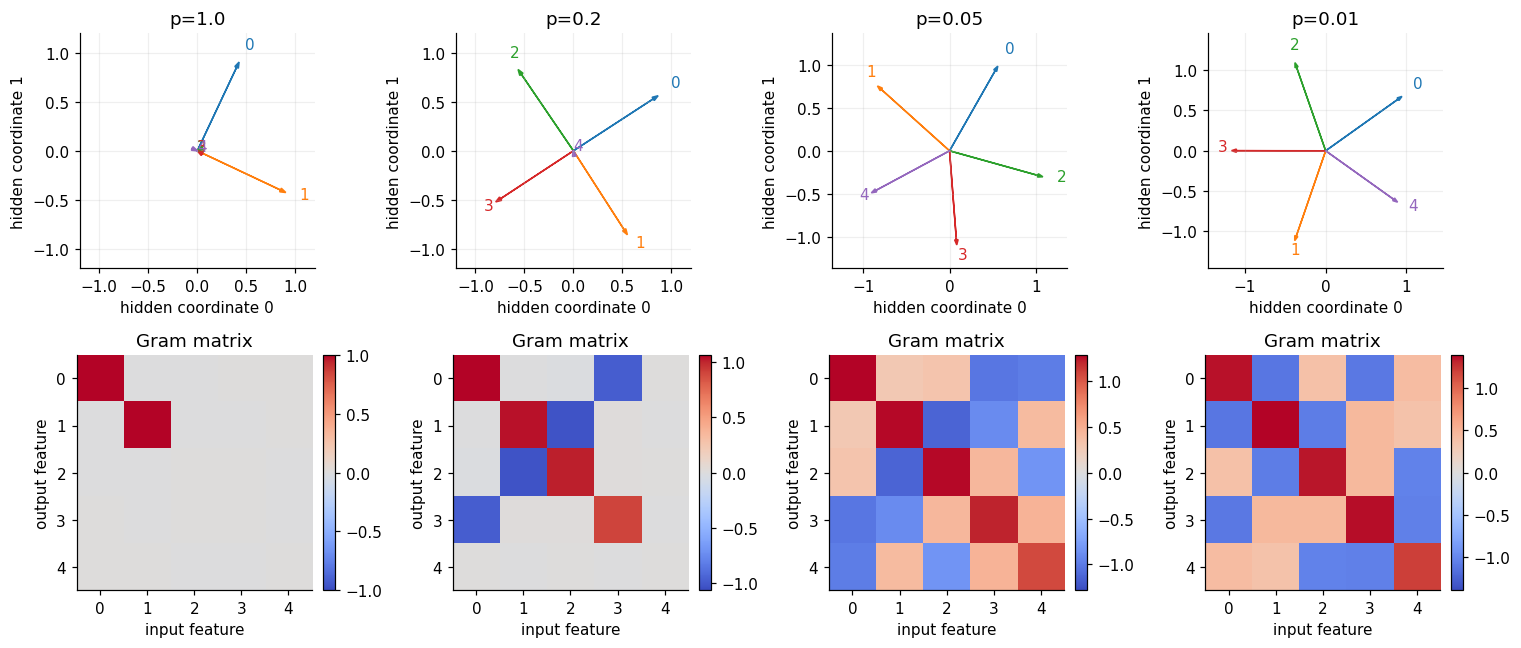

In [ ]:
started=time.perf_counter()
experiments={}
for p in [1.0,.2,.05,.01]:
    model,seed_losses=best_of_seeds(n=5,m=2,p=p,importance=I5)
    experiments[p]=model
    print(f'p={p:4.2f}; common-validation losses by seed:',np.round(seed_losses,6))
print('Training seconds:',round(time.perf_counter()-started,2))

fig,axs=plt.subplots(2,4,figsize=(14,6))
for col,(p,model) in enumerate(experiments.items()):
    arrows(axs[0,col],model['W'],f'p={p}')
    heatmap(axs[1,col],model['W'].T@model['W'],'Gram matrix')
plt.tight_layout();plt.show()


## 19. Measure what the pictures suggest

We report several diagnostics because each sees a different failure mode.

* **Column norm:** is a feature given a nontrivial arrow? Norm near zero suggests it is ignored.
* **Single-feature probe error:** activate feature $i$ alone at many strengths; test the whole output. This detects self-distortion and cross-talk without confounding co-occurrence frequency.
* **Error at active entries:** how well are present features reconstructed?
* **Error at inactive entries:** how much false output appears at absent features?
* **Zero baseline:** what loss would a model get by always predicting zero?

The last two conditional means below average entries, not feature-weighted sums. They diagnose behaviour; they are not the training objective. We also show objective divided by zero-baseline loss, a useful scale adjustment that still does not make different distributions identical tasks.

A “represented count” based on a norm threshold is a heuristic. Change the threshold and check whether the conclusion survives. For a rigorous claim, inspect conditional recovery and compare sensible baselines as well.


In [ ]:
def diagnostics(model,seed=700):
    W=model['W']; n=W.shape[1]
    X=sample_data(np.random.default_rng(seed),30000,n,model['p'])
    Y=predict(model,X)
    active=X!=0; err=(Y-X)**2
    loss=weighted_mse(Y,X,model['importance'])
    baseline=weighted_mse(np.zeros_like(X),X,model['importance'])
    strengths=np.linspace(.05,1,30)
    probes=np.eye(n)[:,None,:]*strengths[None,:,None]
    P=probes.reshape(-1,n)
    probe_error=((predict(model,P)-P)**2).sum(axis=1).reshape(n,-1).mean(axis=1)
    return dict(loss=loss,zero_baseline=baseline,ratio=loss/max(baseline,1e-12),
                active_mse=err[active].mean(),
                inactive_mse=err[~active].mean() if (~active).any() else np.nan,
                norms=np.linalg.norm(W,axis=0),probe_error=probe_error)

for p,model in experiments.items():
    d=diagnostics(model)
    print(f'p={p}: loss/zero-baseline={d["ratio"]:.3f}, '
          f'active MSE={d["active_mse"]:.4f}, inactive MSE={d["inactive_mse"]:.4f}')
    print('  norms:',np.round(d['norms'],3))
    print('  isolated probe errors:',np.round(d['probe_error'],4))


p=1.0: loss/zero-baseline=0.097, active MSE=0.0499, inactive MSE=nan
  norms: [1.001 0.998 0.002 0.001 0.002]
  isolated probe errors: [0.764 0.765 0.588 0.596 0.589]
p=0.2: loss/zero-baseline=0.160, active MSE=0.0736, inactive MSE=0.0020
  norms: [1.031 1.018 1.003 0.949 0.005]
  isolated probe errors: [0.011 0.011 0.011 0.012 0.263]
p=0.05: loss/zero-baseline=0.100, active MSE=0.0289, inactive MSE=0.0005
  norms: [1.131 1.125 1.125 1.096 1.031]
  isolated probe errors: [0.008 0.019 0.014 0.044 0.031]
p=0.01: loss/zero-baseline=0.060, active MSE=0.0150, inactive MSE=0.0001
  norms: [1.162 1.179 1.158 1.167 1.096]
  isolated probe errors: [0.017 0.021 0.019 0.019 0.019]


## 20. Compare against the actual linear baseline

Instead of hoping stochastic optimization finds the linear optimum, construct it directly for our independent equal-probability inputs. Retain the two highest-priority coordinates and use the means for ignored ones. This is a stronger and more transparent comparison than an undertrained linear model.

The output ReLU model has more representational flexibility, but optimization is not guaranteed to exploit it. On the dense distribution, a finite run might underperform the analytic linear solution. That would be an optimization observation, not evidence that adding ReLU reduces the set of possible functions on nonnegative inputs.

The bias-only baseline is also useful: predict $p/2$ for each feature. It beats predicting zero on average because it uses the unconditional mean. But on rare genuinely active features it cannot respond to the input at all.


In [ ]:
for p,model in experiments.items():
    X=sample_data(np.random.default_rng(202),30000,5,p)
    WL,bL=optimal_coordinate_linear(5,2,p,I5)
    linear=X@WL.T@WL+bL
    mean_only=np.full_like(X,p/2)
    print(f'p={p}: linear={weighted_mse(linear,X,I5):.6f}; '
          f'ReLU={weighted_mse(predict(model,X),X,I5):.6f}; '
          f'mean-only={weighted_mse(mean_only,X,I5):.6f}')


p=1.0: linear=0.089844; ReLU=0.089894; mean-only=0.231362
p=0.2: linear=0.060732; ReLU=0.029621; mean-only=0.157164
p=0.05: linear=0.017334; ReLU=0.004829; mean-only=0.043808
p=0.01: linear=0.003434; ReLU=0.000592; mean-only=0.008743


### Read the executed results before moving on

In the included run, the dense model has held-out loss about **0.0899**, very close to the analytic linear baseline of **0.0898**. Its first two feature columns have norms near 1, while the other three are near zero. It has largely chosen which features to keep.

At active probability **0.05**, all five columns have substantial norms, and the nonlinear model has loss about **0.0048**, compared with **0.0173** for the analytic coordinate linear baseline on the same samples. The extra coverage is worth the interference under this sparse distribution. The Gram matrix shows that this is shared representation, rather than five independent dimensions somehow appearing inside two coordinates.

The dense model has surprisingly poor isolated-feature probe scores. Those probes contain many zeros, which are atypical under its dense training distribution. In particular, ignored outputs retain their learned mean predictions even when a probe sets those coordinates to zero. The probe is intentionally testing a different conditional situation; interpret it together with the in-distribution loss rather than treating it as a contradiction.

Your rerun can produce slightly different numbers. The important comparison is within one data distribution, against a clear baseline, with the geometry explaining the error pattern.

# Part 5 — phase changes without mystical physics
## 21. A fully solvable miniature competition

Consider two nonnegative independent features and one hidden dimension. Let $I_1=1,I_2=q>0$. Compare **three fixed strategies with zero bias and unit nonzero weights**:

1. Keep feature 1: $W=[1,0]$.
2. Keep feature 2: $W=[0,1]$.
3. Share antipodally: $W=[1,-1]$.

Keeping feature 1 loses only feature 2, so $L_1=qp/3$. Keeping feature 2 gives $L_2=p/3$. For the antipodal strategy, errors occur only when both features are active. Suppose their strengths are $u,v$. If $u\ge v$, reconstruction is $(u-v,0)$, so both coordinates have error magnitude $v$. If $v\ge u$, both have error magnitude $u$. Thus

$$\ell_{\pm}(u,v)=(1+q)\min(u,v)^2.$$

Average over the unit square. The two triangles are symmetric:

$$\mathbb E[\min(u,v)^2]
=2\int_0^1v^2(1-v)\,dv
=2\left(\frac13-\frac14\right)=\frac16.$$

Multiplying by co-occurrence probability gives

$$\boxed{L_{\pm}=\frac{(1+q)p^2}{6},\quad L_1=\frac{qp}{3},\quad L_2=\frac p3.}$$

This is an exact calculation **within these fixed candidates**, not an exact solution of the full trainable, biased model. Optimizing norms, biases, or same-sign weights can produce additional solutions.


In [ ]:
local=np.random.default_rng(123)
X=sample_data(local,350000,2,.2)
q=.7
candidates=[np.array([[1.,0.]]),np.array([[0.,1.]]),np.array([[1.,-1.]])]
exact=[q*.2/3,.2/3,(1+q)*.2**2/6]
for label,W,expected in zip(['keep 1','keep 2','antipodal'],candidates,exact):
    observed=weighted_mse(relu(X@W.T@W),X,np.array([1,q]))
    print(label,'Monte Carlo:',round(observed,6),'analytic:',round(expected,6))
    assert abs(observed-expected)<.001


keep 1 Monte Carlo: 0.046527 analytic: 0.046667
keep 2 Monte Carlo: 0.066653 analytic: 0.066667
antipodal Monte Carlo: 0.011376 analytic: 0.011333


## 22. Derive and plot the candidate phase diagram

Antipodal sharing beats keeping feature 1 when

$$\frac{(1+q)p^2}{6}<\frac{qp}{3}\quad\Longleftrightarrow\quad
p<\frac{2q}{1+q},$$

assuming $p>0$. It beats keeping feature 2 when $p<2/(1+q)$. Therefore sharing wins among the three if

$$p<\frac{2\min(q,1)}{1+q}.$$

For equal importance $(q=1)$, sharing is better for every $0<p<1$ in this restricted comparison, and ties at $p=1$. For highly unequal importance the sharing region shrinks. A low-priority feature must be sufficiently rare before its extra reconstruction benefit justifies damaging a high-priority one.

A **phase diagram** labels which strategy wins at each setting. The three individual loss functions are smooth, but their minimum can have a kink where the winning strategy changes. The optimizer's parameters can switch abruptly even though all three loss surfaces vary smoothly. This is the useful physics analogy; no literal thermodynamic material is hiding in the laptop.

The full paper studies trained models and richer analytic candidates. Our plot illustrates the logic cleanly; it is not their empirical phase diagram. Subsequent replication comments also discuss additional regimes and local minima. A three-colour teaching plot must not be mistaken for a classification theorem for all solutions.


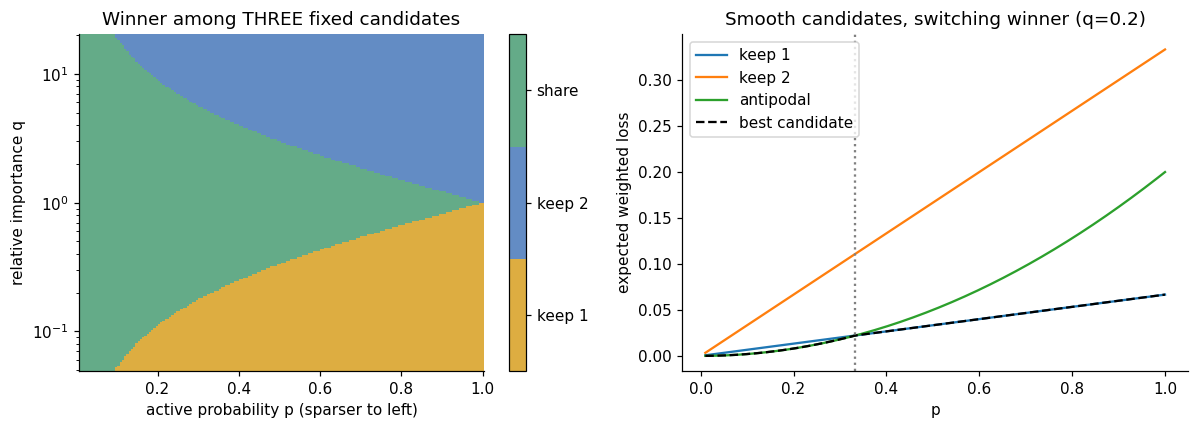

In [ ]:
from matplotlib.colors import ListedColormap
ps=np.linspace(.01,1,180)
qs=np.geomspace(.05,20,180)
PP,QQ=np.meshgrid(ps,qs)
losses=np.stack([QQ*PP/3,PP/3,(1+QQ)*PP**2/6])
winner=np.argmin(losses,axis=0)
fig,axs=plt.subplots(1,2,figsize=(11,4))
im=axs[0].pcolormesh(ps,qs,winner,cmap=ListedColormap(['#ddad41','#638cc4','#64ab88']),
                      shading='auto',vmin=-.5,vmax=2.5)
axs[0].set(yscale='log',xlabel='active probability p (sparser to left)',
           ylabel='relative importance q',title='Winner among THREE fixed candidates')
cb=plt.colorbar(im,ax=axs[0],ticks=[0,1,2]);cb.ax.set_yticklabels(['keep 1','keep 2','share'])
q=.2
curves=np.stack([q*ps/3,ps/3,(1+q)*ps**2/6])
for line,label in zip(curves,['keep 1','keep 2','antipodal']):
    axs[1].plot(ps,line,label=label)
axs[1].plot(ps,curves.min(axis=0),'k--',label='best candidate')
axs[1].axvline(2*q/(1+q),color='grey',ls=':')
axs[1].set(xlabel='p',ylabel='expected weighted loss',title='Smooth candidates, switching winner (q=0.2)')
axs[1].legend();plt.tight_layout();plt.show()


## 23. Why the complete phase problem is harder

The restricted candidates forced weights to be 0 or $\pm1$ and bias to zero. A trained model can adjust continuous magnitudes, use nonzero biases, or encode both features with the same sign and accept a different pattern of confusion. Even this tiny nonconvex problem can have multiple local minima.

**Nonconvex** means the landscape can have several valleys. Finding a valley does not prove that it is the lowest. A phase boundary measured from one seed, 300 training steps, and a thresholded norm may partly describe optimization failure.

For a research-grade sweep: choose a grid of $p,q$, run many restarts at each point, compare on a common large validation sample per task, inspect weights continuously before assigning labels, increase training budget near boundaries, and report uncertainty. Never present a sparse grid as an exact transition curve.

**Exercise:** alter the candidate plot to include a mean-only predictor. Its optimal loss is $(1+q)(p/3-p^2/4)$. Does it win anywhere among the three candidates? If so, what does that tell you about drawing universal conclusions from a restricted set of solutions?


# Part 6 — why geometry appears
## 24. Packing arrows, not storing spreadsheet cells

When features have similar importance and activation probability, the objective treats them symmetrically. Unit feature arrows tend to benefit from keeping positive overlap small. This is related to **spherical coding** and point-packing problems: place points on a sphere so some interaction cost is low.

The analogy to the Thomson problem is structural, not exact. The classic Thomson problem minimizes electrostatic repulsion among charges on a sphere. Our one-feature reconstruction penalty depends on positive dot products, importance, norms, biases, and event frequencies. Change the energy, and the preferred arrangement can change.

Some useful constructions:

| Construction | Feature arrows | Ambient dimensions | Equal share per feature in the symmetric case |
|---|---:|---:|---:|
| Antipodal pair (digon) | 2 | 1 | (1/2) |
| Equilateral triangle | 3 | 2 | (2/3) |
| Regular pentagon | 5 | 2 | (2/5) |
| Regular tetrahedron | 4 | 3 | (3/4) |

A triangle has pairwise dot products (-1/2). A tetrahedron has (-1/3). With unit arrows, zero bias, and exactly one nonnegative active feature, both reconstruct perfectly using the tied ReLU decoder. More than one simultaneous feature can still interfere destructively.

The pentagon necessarily contains positive overlaps. It therefore illustrates a different bargain: fit even more arrows while accepting some single-feature cross-talk, possibly reduced by negative biases.


pair single-feature unit-probe MSE: 0.0
triangle single-feature unit-probe MSE: 1.3695501826753676e-33
pentagon single-feature unit-probe MSE: 0.03819660112501052
tetrahedron single-feature unit-probe MSE: 1.232595164407831e-32


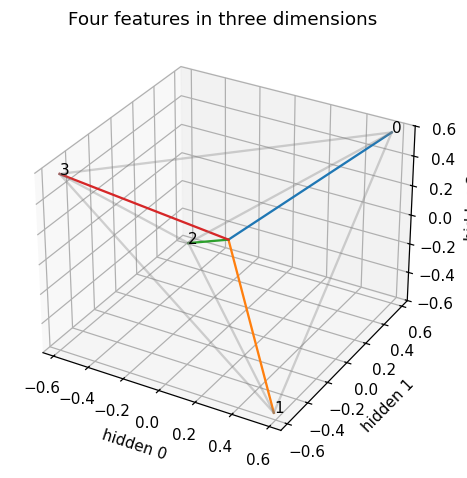

In [ ]:
W_triangle=polygon_weights(3)
W_tetra=np.array([[1,1,-1,-1],[1,-1,1,-1],[1,-1,-1,1]],dtype=float)/np.sqrt(3)
for name,W in [('pair',W_pair),('triangle',W_triangle),('pentagon',W5),('tetrahedron',W_tetra)]:
    E=np.eye(W.shape[1])
    Y=relu(E@W.T@W)
    print(name,'single-feature unit-probe MSE:',np.mean((Y-E)**2))
    if name!='pentagon': assert np.allclose(Y,E)

fig=plt.figure(figsize=(6,5))
ax=fig.add_subplot(111,projection='3d')
for i,v in enumerate(W_tetra.T):
    ax.plot([0,v[0]],[0,v[1]],[0,v[2]])
    ax.text(*v,str(i))
for i in range(4):
    for j in range(i):
        ax.plot(*W_tetra[:,[i,j]],color='grey',alpha=.35)
ax.set(xlabel='hidden 0',ylabel='hidden 1',zlabel='hidden 2',title='Four features in three dimensions')
plt.show()


## 25. Feature dimensionality: what can “two-fifths of a dimension” mean?

The paper defines a geometric diagnostic. For a nonzero feature vector $w_i$, let $\hat w_i=w_i/\|w_i\|_2$, then

$$D_i=\frac{\|w_i\|_2^2}{\sum_j(\hat w_i\cdot w_j)^2}
=\frac{\|w_i\|_2^4}{\sum_j(w_i\cdot w_j)^2}.$$

The second form comes from substituting $\hat w_i=w_i/\|w_i\|_2$, then multiplying numerator and denominator by $\|w_i\|_2^2$. If $w_i=0$, define $D_i=0$.

The denominator includes **the feature itself**. Its self-term is $\|w_i\|_2^4$, so $0<D_i\le1$ for a nonzero column. A feature orthogonal to every other column has $D_i=1$. Two equal-length antipodal features each get (1/2). A symmetric pentagon gets (2/5).

This number is an allocation diagnostic, not an integer rank, a probability, a literal fractional neuron, or a measured mutual information. If arrow lengths differ, the distribution of $D_i$ can be unintuitive. The total $\sum_iD_i$ is **not automatically equal to $m$** for arbitrary $W$.

Why equality in symmetric examples? For a well-spread equal-norm tight frame, $WW^\top=c\mathrm{Id}_m$. Then $\sum_j(w_i\cdot w_j)^2=w_i^\top WW^\top w_i=c\|w_i\|_2^2$, giving $D_i=\|w_i\|_2^2/c$. Summing gives $\sum_iD_i=\operatorname{tr}(WW^\top)/c=m$. The **trace** is the sum of diagonal entries. This is a condition-based explanation, not a general identity.


In [ ]:
def dimensionality(W):
    G=W.T@W
    norm2=np.diag(G)
    denom=(G*G).sum(axis=1)
    return np.divide(norm2**2,denom,out=np.zeros_like(norm2),where=denom>1e-20)

for name,W in [('pair',W_pair),('triangle',W_triangle),('pentagon',W5),('tetrahedron',W_tetra)]:
    print(name,'D =',dimensionality(W),'sum =',dimensionality(W).sum())
W_unequal=np.array([[1.,2.]])
print('Unequal collinear columns:',dimensionality(W_unequal),
      'sum:',dimensionality(W_unequal).sum())
W_nonisotropic=np.array([[1.,1.,0.],[0.,1.,1.]])
print('Non-isotropic 2D example D sum:',dimensionality(W_nonisotropic).sum(),
      '(need not equal 2)')
assert np.allclose(dimensionality(W5),.4)
assert np.allclose(dimensionality(W_tetra),.75)


pair D = [0.5 0.5] sum = 1.0
triangle D = [0.667 0.667 0.667] sum = 2.0
pentagon D = [0.4 0.4 0.4 0.4 0.4] sum = 2.0
tetrahedron D = [0.75 0.75 0.75 0.75] sum = 3.0
Unequal collinear columns: [0.2 0.8] sum: 1.0
Non-isotropic 2D example D sum: 1.6666666666666665 (need not equal 2)


## 26. Orthogonal groups and the tegum-product idea

Suppose one hidden axis hosts an antipodal pair and the perpendicular plane hosts a triangle. The five feature arrows together occupy three dimensions. Features in different groups have dot product zero, so they do not interfere through the Gram matrix.

The geometric term **tegum product** describes combining polytopes in orthogonal subspaces, using the convex hull of the embedded pieces. For this notebook, the operational point is enough: separate interference groups can coexist without interacting.

If we draw a graph with features as nodes and nonzero dot products as edges, orthogonal groups become disconnected components. A visually complicated high-dimensional model may therefore consist of several small simple geometric components.

This also explains why counting all features against all dimensions can hide local structure. Globally, five arrows exceed three dimensions. Locally, two arrows share one dimension and three arrows share two, with no cross-group interference.

Do not overgeneralize the clean polytopes. Symmetric synthetic data and the tied architecture create special incentives. Real language features have complicated co-occurrence, varying importance, and representations influenced by many other computations.


Dimensionalities: [0.5   0.5   0.667 0.667 0.667]
Cross-group Gram entries: [[0. 0. 0.]
 [0. 0. 0.]]


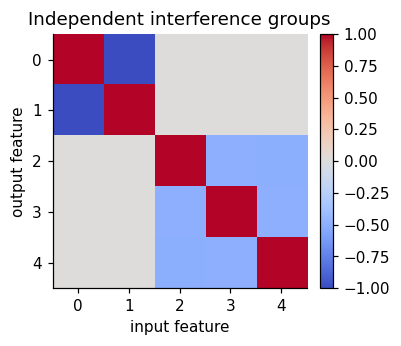

In [ ]:
W_groups=np.zeros((3,5))
W_groups[0,:2]=[1,-1]
W_groups[1:,2:]=W_triangle
print('Dimensionalities:',dimensionality(W_groups))
print('Cross-group Gram entries:',W_groups[:,:2].T@W_groups[:,2:])
fig,ax=plt.subplots(figsize=(4,3))
heatmap(ax,W_groups.T@W_groups,'Independent interference groups')
plt.show()


## 27. Inspect the geometry actually learned

An arrow plot answers “where do columns point?” A Gram plot answers “which features interfere?” A dimensionality plot answers “how is each direction shared according to this diagnostic?” These are related views, not interchangeable proofs.

For example, a column can shrink toward zero while its dimensionality remains sizeable if all arrows shrink together. Always inspect the norm alongside $D_i$. Thresholding tiny columns before plotting can be helpful for visualization, but report that choice.

The paper studies larger uniform models to expose concentrations near simple fractional values. Our five-feature importance-weighted runs are deliberately non-uniform, so perfect fractions are not expected. Failing to see a clean pentagon here does not contradict the existence of superposition.


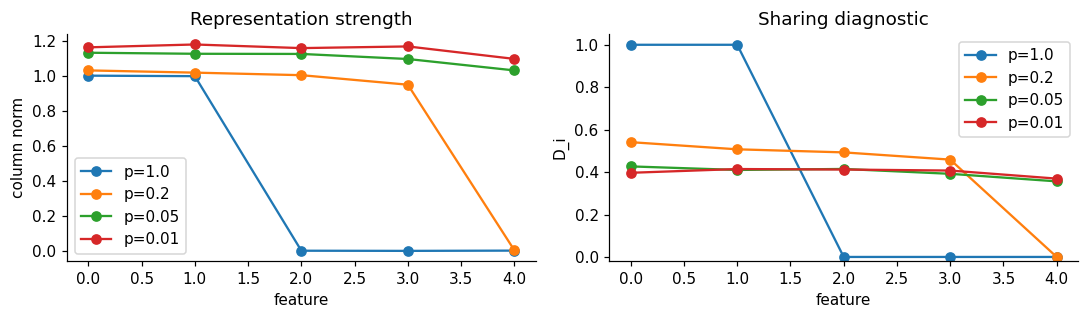

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(10,3))
for p,model in experiments.items():
    axs[0].plot(np.arange(5),np.linalg.norm(model['W'],axis=0),'o-',label=f'p={p}')
    axs[1].plot(np.arange(5),dimensionality(model['W']),'o-',label=f'p={p}')
axs[0].set(xlabel='feature',ylabel='column norm',title='Representation strength')
axs[1].set(xlabel='feature',ylabel='D_i',title='Sharing diagnostic',ylim=(-.02,1.05))
axs[0].legend();axs[1].legend();plt.tight_layout();plt.show()


# Part 7 — co-occurrence changes who should share
## 28. Correlated, independent, and mutually exclusive features

The independent-feature assumption is convenient, but it removes an important part of real data. Shoes and feet often appear together; “daytime” and “night-time” may exclude one another in a particular task. The cost of destructive interference depends on which features are simultaneously active.

For a simple controlled comparison with two features and marginal activation probability $p\le1/2$:

* **Independent:** flip two separate coins. Both active with probability $p^2$.
* **Co-active:** flip one coin with probability $p$, activating both. Their strengths are independently sampled. Both active with probability $p$.
* **Exclusive:** choose feature 1 with probability $p$, feature 2 with probability $p$, or neither with probability $1-2p$. Both active with probability zero.

All three have the same marginal activation rate for each feature. This control matters: otherwise a difference attributed to correlation might really come from changing feature frequency.

Our antipodal encoder reconstructs exclusive inputs exactly. It performs worse when the pair regularly co-occurs. This is a causal demonstration using a fixed encoder: we changed the distribution while keeping weights, importance, and marginals fixed. It does not by itself show which geometry an optimized larger model will choose.


In [ ]:
def pair_distribution(rng,batch,p,mode):
    values=rng.random((batch,2))
    if mode=='independent':
        mask=rng.random((batch,2))<p
    elif mode=='coactive':
        mask=np.repeat(rng.random((batch,1))<p,2,axis=1)
    elif mode=='exclusive':
        if not 0<=p<=.5: raise ValueError('Exclusive pair requires p <= .5')
        coin=rng.random(batch)
        mask=np.stack([coin<p,(coin>=p)&(coin<2*p)],axis=1)
    else: raise ValueError(mode)
    return values*mask

for mode in ['independent','coactive','exclusive']:
    X=pair_distribution(np.random.default_rng(8),150000,.15,mode)
    Y=relu(X@W_pair.T@W_pair)
    print(mode,'marginals:',np.mean(X!=0,axis=0),
          'pair loss:',round(weighted_mse(Y,X,np.ones(2)),5))


independent marginals: [0.151 0.149] pair loss: 0.00772
coactive marginals: [0.15 0.15] pair loss: 0.04955
exclusive marginals: [0.15 0.15] pair loss: 0.0


## 29. Local bases and collapsing correlated features

If several features frequently co-occur, orthogonal directions let them vary independently without destructive cross-talk. If there is enough space, assigning those features to separate orthogonal groups is attractive. Across rarely co-occurring groups, shared dimensions can be cheaper.

This motivates a **local basis**: a particular subset of the data may activate features that are approximately orthogonal even though the complete feature collection is overcomplete. Local interpretability does not imply global interpretability.

When space is too constrained, two strongly correlated features may be approximated by their shared component instead of separately recovered. If $x_1\approx x_2$, encoding $x_1+x_2$ captures the large common variation while losing $x_1-x_2$. That is close to the logic of principal component analysis (PCA).

Correlation therefore does not merely “increase superposition.” It changes which representations are economical. Depending on capacity and distribution, an optimizer can separate features, share directions with controlled interference, or merge them into a common component.

**Optional experiment:** create three correlated pairs in six features, fit a two-dimensional bottleneck at several $p$ values, and compare their Gram blocks. Keep marginal activation probabilities fixed across conditions. Do not assume a sample correlation coefficient alone specifies the joint distribution.


## 30. Learning dynamics: watch the movie, not only the final frame

Our training function stored checkpoints. A smooth-ish loss curve does not prove that each feature's representation changed smoothly. Norms, angles, and dimensionality can reorganize over shorter periods.

The paper reports examples of sharp geometric reorganizations. For our run, the correct practice is to inspect what happened, not to force the same narrative onto every seed. A small CPU example may converge smoothly, jump, or simply remain in an imperfect valley.

We use fixed validation data for the loss history so batch noise does not masquerade as progress. Checkpoints are 100 steps apart; changes faster than that are not resolved. Plot more frequent checkpoints if the mechanism of a transition is your research question.

“Energy level” is an analogy for recurring geometric allocations. It does not mean the optimizer obeys quantum mechanics or that loss can only take discrete values. Likewise, a late loss drop is not automatically **grokking**, which usually concerns delayed generalization after memorization and needs appropriate train/test evidence.


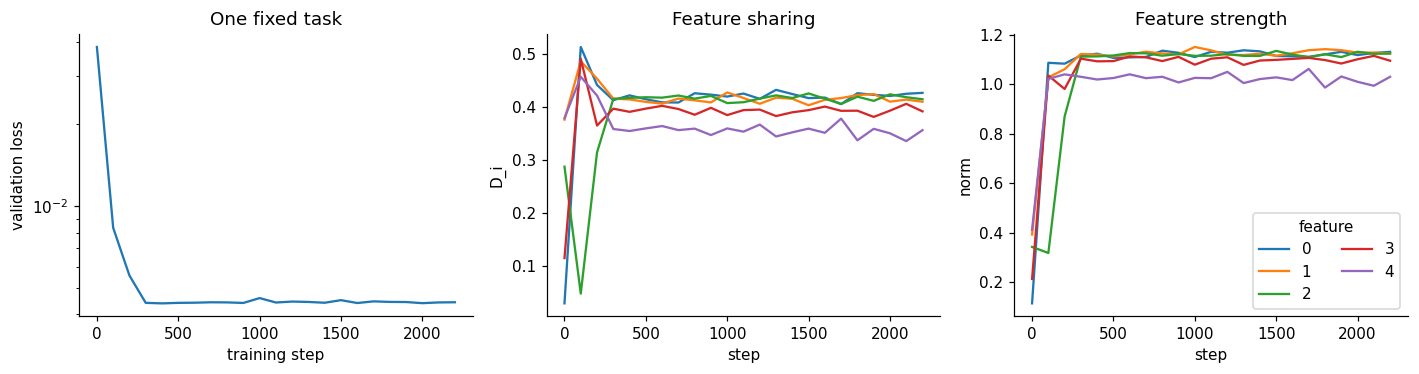

In [ ]:
chosen=experiments[.05]
history=chosen['history']
steps=np.array([r['step'] for r in history])
D_history=np.stack([dimensionality(r['W']) for r in history])
norm_history=np.stack([np.linalg.norm(r['W'],axis=0) for r in history])
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
axs[0].plot(steps,[r['loss'] for r in history])
axs[0].set(xlabel='training step',ylabel='validation loss',yscale='log',title='One fixed task')
for i in range(5):
    axs[1].plot(steps,D_history[:,i],label=str(i))
    axs[2].plot(steps,norm_history[:,i],label=str(i))
axs[1].set(xlabel='step',ylabel='D_i',title='Feature sharing')
axs[2].set(xlabel='step',ylabel='norm',title='Feature strength')
axs[2].legend(title='feature',ncol=2);plt.tight_layout();plt.show()


# Part 8 — robustness and the meaning of a neuron
## 31. An adversarial direction hiding in the Gram matrix

For the output-ReLU model, preactivation $a_i=g_i^\top x+b_i$, where $g_i^\top$ is row $i$ of $G$. An input perturbation $\delta$ changes it by $g_i^\top\delta$.

If the attacker is constrained by $\|\delta\|_2\le\epsilon$, the greatest increase in that preactivation is $\epsilon\|g_i\|_2$, achieved by $\delta=\epsilon g_i/\|g_i\|_2$. This follows from the Cauchy–Schwarz inequality: a fixed-length arrow has its largest projection when it aligns with the target direction.

To isolate interference, set the target coordinate of the attack to zero and optimize over the other coordinates. Let $c_i$ be row $g_i$ with its diagonal entry removed. Then $\delta=\epsilon c_i/\|c_i\|_2$ changes the target preactivation through other features only.

**Threat-model warning:** this construction allows signed continuous perturbations of synthetic inputs. It may leave the nonnegative data domain and does not model a malicious text prompt. It is an exact maximizer of one preactivation under that constraint, not necessarily a maximizer of total post-ReLU loss.

Cross-talk gives one route to vulnerability. This does not establish that all adversarial examples in real networks arise from superposition. Robustness has multiple mechanisms, and bounds depend on input constraints, margins, and decoder behaviour.


In [ ]:
G=W5.T@W5
target_feature=0
cross=G[target_feature].copy();cross[target_feature]=0
epsilon=.2
attack=epsilon*cross/np.linalg.norm(cross)
clean=np.zeros(5)
print('Attack norm:',np.linalg.norm(attack),'target input unchanged:',attack[0])
print('Target preactivation increase:',G[target_feature]@attack)
print('Analytic maximum:',epsilon*np.linalg.norm(cross))
print('Clean output:',relu(clean@G))
print('Perturbed output:',relu((clean+attack)@G))
assert np.isclose(G[target_feature]@attack,epsilon*np.linalg.norm(cross))


Attack norm: 0.2 target input unchanged: 0.0
Target preactivation increase: 0.24494897427831783
Analytic maximum: 0.2449489742783178
Clean output: [0. 0. 0. 0. 0.]
Perturbed output: [0.245 0.076 0.    0.    0.076]


## 32. Rotation: a feature direction need not be a neuron

Take any orthogonal hidden-space rotation $R\in\mathbb R^{m\times m}$, satisfying $R^\top R=\mathrm{Id}$. Set $W'=RW$. Then

$$W'^\top W'=W^\top R^\top RW=W^\top W.$$

The entire output-ReLU model therefore computes exactly the same function after rotation. Hidden activations rotate, but reconstructed outputs stay the same. The individual hidden coordinates have no special status in this architecture.

This is what **no privileged basis** means here. The axes are like longitude lines you chose to draw on a globe, not natural seams in the represented information. A feature perfectly aligned with neuron 0 before rotation can be distributed across both neurons afterward without changing its meaning or recoverability.

Now put a coordinatewise nonlinearity inside: $h=\operatorname{ReLU}(Wx)$. Arbitrary rotations no longer commute with it:

$$\operatorname{ReLU}(Rz)\ne R\operatorname{ReLU}(z)\quad\text{in general}.$$

The hidden coordinates now matter to computation. This can create pressure for some features to align with neurons. It does not guarantee every neuron is monosemantic. Also, permutations of equivalent neurons can remain symmetries.


Output-model rotation identity verified.
ReLU(Rz): [1.012 0.369]
R ReLU(z): [0.745 0.667]


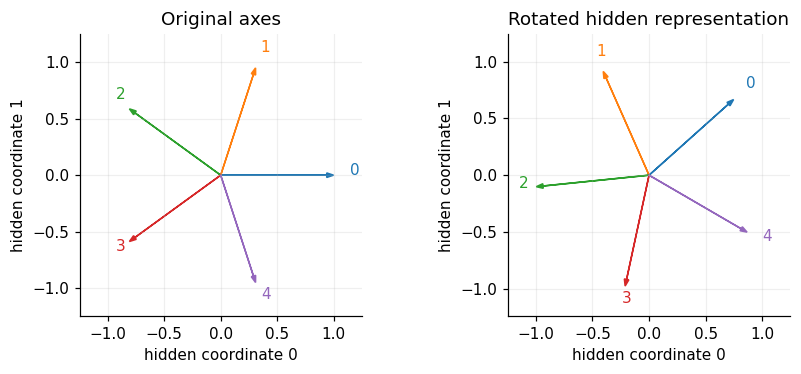

In [ ]:
theta=.73
R=np.array([[np.cos(theta),-np.sin(theta)],
            [np.sin(theta), np.cos(theta)]])
W_rotated=R@W5
X=sample_data(np.random.default_rng(11),1000,5,.1)
assert np.allclose(W_rotated.T@W_rotated,W5.T@W5)
assert np.allclose(relu(X@W5.T@W5),relu(X@W_rotated.T@W_rotated))
print('Output-model rotation identity verified.')
z=np.array([1.,-.4])
print('ReLU(Rz):',relu(R@z))
print('R ReLU(z):',R@relu(z))
fig,axs=plt.subplots(1,2,figsize=(8,3.5))
arrows(axs[0],W5,'Original axes')
arrows(axs[1],W_rotated,'Rotated hidden representation')
plt.tight_layout();plt.show()


## 33. Train the hidden-ReLU variant, and know its limitation

The architecture is now

$$h=\operatorname{ReLU}(Wx),\qquad
\hat x=\operatorname{ReLU}(W^\top h+b).$$

This is a different model class from the one used in the first experiments. Our gradient implementation already supports it. We visualize the actual $W$ because its rows correspond to computationally meaningful hidden units; its columns still connect known input features to those units.

**Status: small illustrative training run.** Hidden-ReLU models can be harder to optimize, and the original work used many restarts for selected results. Two short runs cannot reproduce that search.

There is a structural weakness in this identity-reconstruction task: it does not require the hidden nonlinearity to do anything useful. If the model can keep hidden preactivations positive on the data distribution, the ReLU effectively becomes linear there. Hidden biases or aggregate contributions from many features can facilitate this escape. This motivates the next part, where the target function itself needs nonlinearity.


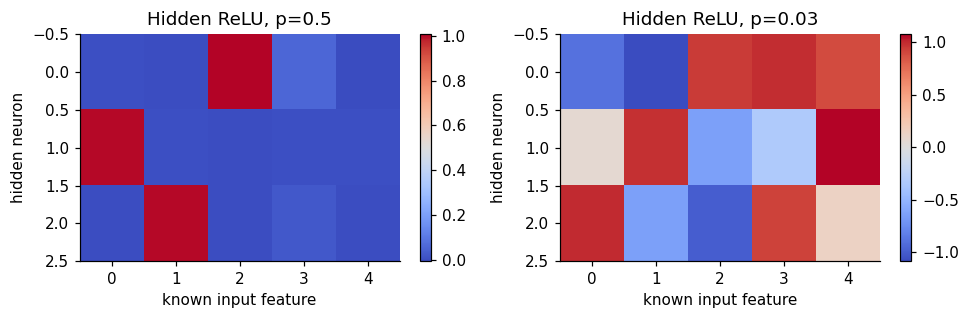

In [ ]:
hidden_models=[]
for p in [.5,.03]:
    model,_=best_of_seeds(seeds=(4,5),n=5,m=3,p=p,importance=I5,
                          hidden_relu=True,steps=2200)
    hidden_models.append(model)
fig,axs=plt.subplots(1,2,figsize=(9,3))
for ax,model in zip(axs,hidden_models):
    im=ax.imshow(model['W'],cmap='coolwarm',aspect='auto')
    ax.set(xlabel='known input feature',ylabel='hidden neuron',
           title=f'Hidden ReLU, p={model["p"]}')
    plt.colorbar(im,ax=ax)
plt.tight_layout();plt.show()


# Part 9 — do computation, not only storage
## 34. Absolute value gives the hidden nonlinearity a job

For a scalar $t$, absolute value $\lvert t\rvert$ is its distance from zero: $|-0.7|=0.7$ and $|0.7|=0.7$. It has a simple ReLU circuit:

$$|t|=\operatorname{ReLU}(t)+\operatorname{ReLU}(-t).$$

One unit handles the positive half and another handles the negative half. For $n$ independent signed inputs, a straightforward construction uses $2n$ hidden units.

The input distribution changes: when active, $x_i\sim\operatorname{Uniform}(-1,1)$. The target changes to $y_i=|x_i|$. The weights are now **untied**:

$$h=\operatorname{ReLU}(Ax),\qquad
\hat y=\operatorname{ReLU}(Bh+b),$$

where $A\in\mathbb R^{m\times n}$, $B\in\mathbb R^{n\times m}$. We use letters $A,B$ to avoid confusing them with the earlier tied matrix $W$. The paper denotes these as $W_1,W_2$.

If a smaller model approximates several sparse absolute-value computations with mixed hidden units, this is computation through a compressed representation, not just recovering stored inputs. But a generic small neural network's approximation error is not enough to prove an interpretable superposition circuit; inspect single-feature responses, weight patterns, and interactions.


In [ ]:
values=np.array([-1.,-.4,0.,.2,1.])
print('t:',values)
print('ReLU(t)+ReLU(-t):',relu(values)+relu(-values))
assert np.allclose(relu(values)+relu(-values),np.abs(values))

def exact_abs_parameters(n):
    A=np.concatenate([np.eye(n),-np.eye(n)],axis=0)
    B=np.concatenate([np.eye(n),np.eye(n)],axis=1)
    return A,B,np.zeros(n)

A_exact,B_exact,b_exact=exact_abs_parameters(3)
X=np.random.default_rng(3).uniform(-1,1,(100,3))
exact_Y=relu(relu(X@A_exact.T)@B_exact.T+b_exact)
assert np.allclose(exact_Y,np.abs(X))
print('Exact six-neuron absolute-value circuit verified for three inputs.')


t: [-1.  -0.4  0.   0.2  1. ]
ReLU(t)+ReLU(-t): [1.  0.4 0.  0.2 1. ]
Exact six-neuron absolute-value circuit verified for three inputs.


## 35. Untied gradients and an inspectable training function

With rows as examples, $Z=XA^\top$, $H=\operatorname{ReLU}(Z)$, $Q=HB^\top+b$, $\hat Y=\operatorname{ReLU}(Q)$, and target $T=|X|$. Start with

$$D=\frac2N(\hat Y-T)\odot I\odot\mathbf1[Q>0].$$

We use $N$ for batch size in this equation so it is not confused with decoder matrix $B$. Then

$$\nabla_B L=D^\top H,\qquad
E=(DB)\odot\mathbf1[Z>0],\qquad
\nabla_A L=E^\top X,\qquad
\nabla_b L=\sum_rD_{r,:}.$$

Unlike tied weights, each matrix has one role and one gradient contribution. Reading the shape is helpful: $D^\top H$ is $n\times m$, exactly the decoder's shape.

We compare a trained compressed model with an explicit exact six-unit circuit and a three-unit circuit that computes only the most important input's absolute value. The latter uses two units and leaves one unused. This is a transparent baseline, **not a proven optimal three-unit architecture**.


Untied gradient maximum discrepancy: 3.510372270643103e-10
Compressed model validation losses: [0.012 0.01  0.009]
One-feature exact circuit baseline: 0.012103002155414357
Zero baseline: 0.02230343458249283


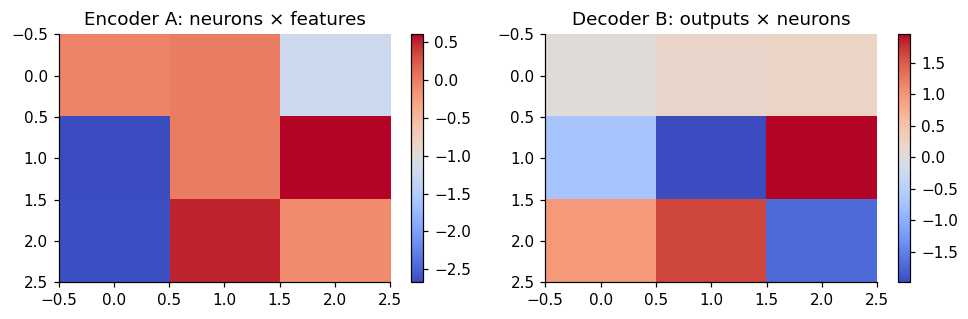

In [ ]:
def abs_forward(X,A,B,b):
    Z=X@A.T; H=relu(Z); Q=H@B.T+b; Y=relu(Q)
    return Y,(Z,H,Q)

def abs_loss_grad(X,A,B,b,importance):
    T=np.abs(X)
    Y,(Z,H,Q)=abs_forward(X,A,B,b)
    D=2*(Y-T)*importance/len(X)*(Q>0)
    gB=D.T@H
    gA=((D@B)*(Z>0)).T@X
    return weighted_mse(Y,T,importance),gA,gB,D.sum(axis=0)

def check_abs_gradients():
    local=np.random.default_rng(17)
    X=local.normal(size=(8,3)); A=local.normal(size=(4,3))
    B=local.normal(size=(3,4)); b=local.normal(size=3)
    importance=np.array([1.,.7,.4])
    _,*grads=abs_loss_grad(X,A,B,b,importance)
    errors=[]
    for arr,grad in zip([A,B,b],grads):
        for ix in np.ndindex(arr.shape):
            value=arr[ix];eps=1e-6
            arr[ix]=value+eps; plus=abs_loss_grad(X,A,B,b,importance)[0]
            arr[ix]=value-eps; minus=abs_loss_grad(X,A,B,b,importance)[0]
            arr[ix]=value
            errors.append(abs((plus-minus)/(2*eps)-grad[ix]))
    assert max(errors)<1e-6
    return max(errors)

print('Untied gradient maximum discrepancy:',check_abs_gradients())

def train_abs(n=3,m=3,p=.03,importance=None,steps=3500,seed=0):
    local=np.random.default_rng(seed)
    importance=np.ones(n) if importance is None else np.asarray(importance)
    A=local.normal(0,.4,(m,n));B=local.normal(0,.4,(n,m));b=np.full(n,.03)
    opt=Adam([A,B,b],lr=.008)
    for step in range(steps):
        X=sample_data(local,512,n,p,signed=True)
        _,gA,gB,gb=abs_loss_grad(X,A,B,b,importance)
        opt.step([gA,gB,gb])
    return dict(A=A,B=B,b=b)

Iabs=np.array([1.,.7,.5])
abs_runs=[train_abs(importance=Iabs,seed=i) for i in range(3)]
Xabs=sample_data(np.random.default_rng(444),40000,3,.03,signed=True)
abs_losses=[weighted_mse(abs_forward(Xabs,**r)[0],np.abs(Xabs),Iabs) for r in abs_runs]
abs_model=abs_runs[int(np.argmin(abs_losses))]
print('Compressed model validation losses:',np.round(abs_losses,6))
Ybaseline=np.zeros_like(Xabs);Ybaseline[:,0]=np.abs(Xabs[:,0])
print('One-feature exact circuit baseline:',weighted_mse(Ybaseline,np.abs(Xabs),Iabs))
print('Zero baseline:',weighted_mse(np.zeros_like(Xabs),np.abs(Xabs),Iabs))
fig,axs=plt.subplots(1,2,figsize=(9,3))
for ax,matrix,title in [(axs[0],abs_model['A'],'Encoder A: neurons × features'),
                        (axs[1],abs_model['B'],'Decoder B: outputs × neurons')]:
    im=ax.imshow(matrix,cmap='coolwarm',aspect='auto');ax.set_title(title)
    plt.colorbar(im,ax=ax)
plt.tight_layout();plt.show()


## 36. Probe signs separately before telling a circuit story

Absolute-value computation has two branches per input. A model might recover the positive side of a feature while missing its negative side. Reporting only average training loss hides this asymmetry.

We therefore present each feature alone, varying it continuously from -1 to 1, and plot its own output against $|t|$. Also inspect outputs for *other* features to measure false activations. If a branch is absent, say so; a short run need not rediscover every published motif.

The toy paper's larger absolute-value experiments explore mixed and pure neurons under different sparsity settings. Our tiny fit is an inspectable exercise rather than a claim to reproduce those exact circuits.

One subtle symmetry: a hidden unit's encoder row can be multiplied by $c>0$, and its decoder column divided by $c$, without changing the function. This uses $\operatorname{ReLU}(cz)=c\operatorname{ReLU}(z)$. Raw weight magnitude alone can therefore mislead when comparing untied models.


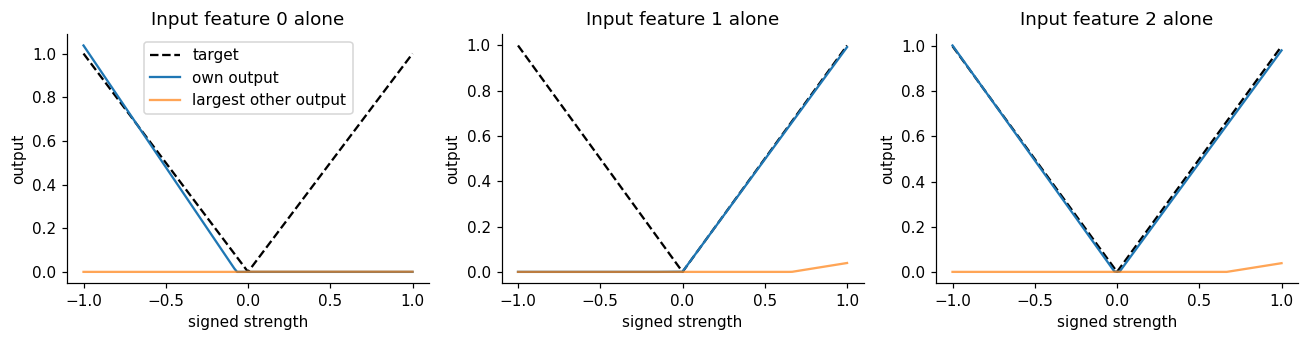

In [ ]:
t=np.linspace(-1,1,121)
fig,axs=plt.subplots(1,3,figsize=(12,3.2))
for i,ax in enumerate(axs):
    P=np.zeros((len(t),3));P[:,i]=t
    Y=abs_forward(P,**abs_model)[0]
    ax.plot(t,np.abs(t),'k--',label='target')
    ax.plot(t,Y[:,i],label='own output')
    ax.plot(t,np.delete(Y,i,axis=1).max(axis=1),label='largest other output',alpha=.7)
    ax.set(title=f'Input feature {i} alone',xlabel='signed strength',ylabel='output')
axs[0].legend();plt.tight_layout();plt.show()


## 37. Asymmetric interference: a worked motif, with its limitations exposed

Consider one hidden unit $h=\operatorname{ReLU}(a u-b v)$, $a,b>0$, feeding two outputs with coefficients $1/a$ and $1/b$. When $u>0,v=0$, the pre-output to $u$ is $u$, while the cross-output to $v$ is $(a/b)u$. When $u=0,v<0$, the response in the other direction is scaled by $b/a$.

Choosing $a\gg b$ makes one direction of cross-talk large and the reverse direction small. The encoder–decoder reciprocal scales preserve a desired branch's self-response while making interference asymmetric. This one unit does not compute both absolute values: it is a **partial motif**.

The paper describes larger circuits in which another unit inhibits an output in the harmful case. The output ReLU can discard the resulting negative preactivation. The conceptual move is to convert an expensive false positive into bounded suppression. A faithful reconstruction of a particular learned circuit requires all relevant weights and sign cases; the single unit below is intentionally not labelled as the full published circuit.

This is another reason to distinguish the tied Gram-matrix model from untied computation. A tied Gram matrix is symmetric: $G_{ij}=G_{ji}$. Untied encoder–decoder pathways, especially with hidden ReLU gates, can create asymmetric effects.


In [ ]:
a,b=2.,.5
inputs=np.array([[1.,0.],[0.,-1.]])
hidden=relu(inputs@np.array([a,-b]))
preoutputs=hidden[:,None]*np.array([1/a,1/b])[None,:]
print('Inputs:',inputs,sep='\n')
print('Single hidden-unit outputs (partial circuit):',preoutputs,sep='\n')
print('Cross/self ratio for first branch:',a/b)
print('Reverse scale:',b/a)


Inputs:
[[ 1.  0.]
 [ 0. -1.]]
Single hidden-unit outputs (partial circuit):
[[1.   4.  ]
 [0.25 1.  ]]
Cross/self ratio for first branch: 4.0
Reverse scale: 0.25


# Part 10 — understand the research picture
## 38. A careful bridge to sparse autoencoders

In the toy model, we know the feature vector $x$ and learn a compressed activation $h=Wx$. In a real model, we observe activations $h$ but generally do not know the underlying feature vector. The interpretability task is almost reversed: infer useful sparse coordinates that explain those activations.

A sparse autoencoder (SAE) commonly learns an encoder $f$ and a dictionary $D$ so that

$$z=f(h),\qquad\hat h=Dz+c,\qquad
\mathcal L_{\rm SAE}=\mathbb E\big[\|h-\hat h\|_2^2+\lambda\|z\|_1\big].$$

Here $z$ can have **more coordinates than $h$** while being sparse on each example. The $L_1$ norm $\|z\|_1=\sum_i|z_i|$ penalizes widespread activation; $\lambda$ controls the reconstruction–sparsity trade-off. Modern SAE objectives and architectures vary, so this is a basic educational form, not a statement that every SAE uses this exact penalty.

The dictionary columns are candidate feature directions. An overcomplete dictionary has more columns than ambient dimensions. The central hope is that a sparse code offers a better explanatory vocabulary than the neuron's original coordinates.

But the toy model is **not itself the standard overcomplete SAE trained on an LLM's activations**. Its input features are known and its bottleneck compresses them. Confusing these directions makes later SAE papers much harder to read.

Also, reconstruction plus sparsity does not prove that learned features are unique, complete, causally meaningful, or cleanly human-interpretable. Features can split, merge, remain undiscovered, or be artifacts of the chosen training distribution. This section is a conceptual extension beyond the paper's core reconstruction experiments.


## 39. Recover a sparse code from our known pentagon dictionary

We can illustrate the reverse problem without fitting an SAE. Take $h=Dz$ for a sparse nonnegative $z$, where $D=W_5$ is already known. Recover an estimate by minimizing

$$F(z)=\frac12\|Dz-h\|_2^2+\lambda\sum_i z_i,\qquad z_i\ge0.$$

The reconstruction gradient is $D^\top(Dz-h)$. A simple proximal-gradient step is

$$z\leftarrow\max\left(0,z-\eta D^\top(Dz-h)-\eta\lambda\right).$$

The `max` both enforces nonnegativity and shrinks small coefficients. This is an iterative inference method with a fixed dictionary, not SAE training. Its purpose is to show that decoding a sparse representation need not be a single tied ReLU step.

Choose step size below $1/\|D\|_2^2$, where $\|D\|_2$ is its largest singular value. This controls the curvature of the reconstruction objective. You do not need singular-value decomposition to run the example; NumPy calculates it.

Positive $\lambda$ deliberately introduces amplitude shrinkage. If the dictionary is ambiguous or the code is too dense, the recovered sparse explanation may differ from the one that generated the input. A dictionary plus an optimizer is not a mind-reading device.


In [ ]:
def sparse_decode_nonnegative(D,h,lam=.01,steps=1000):
    eta=.95/(np.linalg.norm(D,2)**2)
    z=np.zeros(D.shape[1])
    for _ in range(steps):
        z=relu(z-eta*(D.T@(D@z-h))-eta*lam)
    return z

z_true=np.array([.8,0,0,0,0])
h=W5@z_true
one_step=relu(W5.T@h)
iterative=sparse_decode_nonnegative(W5,h)
print('True sparse feature vector:',z_true)
print('One-step tied ReLU decoder:',one_step)
print('Iterative sparse decoder:',iterative)
print('Hidden reconstruction error:',np.linalg.norm(W5@iterative-h))


True sparse feature vector: [0.8 0.  0.  0.  0. ]
One-step tied ReLU decoder: [0.8   0.247 0.    0.    0.247]
Iterative sparse decoder: [0.79 0.   0.   0.   0.  ]
Hidden reconstruction error: 0.01000000000000012


## 40. Why the generalization to LLMs is a hypothesis to test

The synthetic world has labelled independent coordinates, a chosen activation distribution, a transparent objective, and a tiny tied network. LLMs have learned features, correlated language data, residual streams, attention, multilayer nonlinear computation, normalization, and next-token loss. Those differences matter.

The toy result establishes a concrete **mechanism** by which compression, sparse usage, and nonlinearity can make sharing attractive. It is not an exhaustive account of every representation in every language model. The existence of a simple mechanism makes a hypothesis plausible; measuring its prevalence and causal importance requires experiments on the actual model.

Be especially careful with these claims:

| Tempting statement | More defensible formulation |
|---|---|
| Every neuron contains several concepts | Some neurons can participate in several feature representations; inspect the model and distribution |
| Weights look meaningless, so the model has no structure | Useful structure may live in directions and circuits across coordinates |
| A feature is any direction I can name | A useful feature hypothesis needs evidence of coherent representation and causal relevance |
| Superposition stores arbitrarily many facts perfectly | It trades representational coverage against interference under a distribution |
| A sparse decoder fully explains a model | It supplies candidate features and reconstruction; causal computation still needs investigation |
| A pentagon proves how LLM concepts are arranged | It demonstrates a geometry available to a symmetric toy problem |
| Gradient descent wants to hide its thoughts | Optimization follows an objective with no explicit requirement of human-readable coordinates |

The final point connects to your original motivation: there is no reason to expect every learned parameter to be a neatly labelled concept. But “not incentivized to be readable” is not an explanation of the exact geometry. The toy model gives a specific objective-level account we can test.


## 41. A section-by-section companion to reading the original

Use this as a reading protocol. Open the original section, read one paragraph or equation, then answer the corresponding questions in your own words. This guide follows the argument without copying or replacing its prose.

### Background and motivation

**What question is being set up?** Why do interpretable neurons sometimes appear, while other neurons respond to unrelated patterns? Translate “feature” into a property and “neuron” into an activation coordinate. Do not silently assume a one-to-one relationship.

**What assumptions are introduced?** Decomposability says a representation has separately understandable components; linear representation says components correspond to directions. Neither follows merely because a network uses matrices. They are hypotheses about the learned representation.

**Why two forces?** Coordinatewise operations can privilege the neuron's basis, whereas the benefit of representing extra features can encourage non-orthogonal sharing. These are different pressures; neither alone determines all representations.

### Demonstrating superposition — experiment setup

For each symbol, say its type: $x$ is an input vector, $W$ is the encoder parameter matrix, $h$ is a hidden activation, $b$ is an output bias, $I_i$ weights an error. Translate $S_i$ to our $1-p_i$. Explain why having synthetic known coordinates makes the experiment interpretable.

When you see $W^\top Wx$, expand it to $\sum_j(w_i\cdot w_j)x_j$ for output $i$. That expansion is the central equation hiding inside the compact notation. When you see the bias, remember both uses: unconditional means and nonlinear noise thresholds.

### Demonstrating superposition — results and mathematical understanding

Read every heatmap as a matrix with specified axes. A bright diagonal is self-response; off-diagonal entries are cross-talk. Inspect the column norms and the distribution, not only the number of colourful arrows.

For the sparse-event expansion, ask what is summed and what is averaged. Re-derive our one-feature loss. Explain exactly when negative cross-talk is clipped away and when it can suppress a real feature. Recognize the packing analogy as conditional on simplifying assumptions.

### Superposition as a phase change

Identify the axes before interpreting a colour: activation frequency and importance have different effects. Understand “not represented,” “represented with a dedicated direction,” and “represented in sharing” as possible strategies. Re-derive the candidate crossing in Part 5, then ask which freedoms the paper's richer analysis includes.

### Geometry — uniform superposition

“Uniform” means equal data and importance settings across features, not a claim that all real concepts behave identically. Compute the diagnostic $D_i$ yourself for an antipodal pair and triangle. Distinguish a point's ambient dimension, the span's rank, and its allocated feature dimensionality.

When encountering a polytope, translate it into columns of a matrix. Which dots are positive? Which are zero? Which are negative? That translation turns decorative geometry into a mechanistic explanation.

### Geometry — non-uniform superposition

Changing importance or frequency breaks symmetry. Changing correlations alters which collisions are frequent. Ask whether a comparison controls marginal probabilities. When correlated features collapse, distinguish merging a common component from separately recovering both original features.

### Learning dynamics

Read the loss curve alongside the feature geometry over time. Check whether axes are training steps, loss, or dimensionality. A discrete-looking reorganization of geometry can coexist with continuous parameter updates. A suggestive connection to grokking is not an identity between the phenomena.

### Relationship to adversarial examples

Write the attacker constraint explicitly. Does the perturbation remain in the data domain? Is the attack maximizing one output preactivation or the complete loss? Does the analysis concern an optimized average-case model or finite-data overfitting? These are distinct explanations of vulnerability.

### Superposition in a privileged basis

Verify the rotation identity for the linear hidden representation. Then insert hidden ReLU and show where the identity fails. Explain why neuron-aligned interpretation becomes more natural, and why the identity task can let the model evade useful nonlinear computation.

### Computation in superposition

Notice all changes at once: signed inputs, absolute-value targets, hidden nonlinearity, and untied weights. Re-derive the two-unit scalar circuit. Probe positive and negative branches separately. Distinguish a complete learned circuit from a local asymmetric motif.

### Strategic picture, discussion, and related work

Separate the mathematical possibility of an overcomplete explanation from the practical problem of identifying one in a real model. Compare three broad routes: change the model to encourage separability, infer a useful overcomplete feature dictionary afterward, or combine both. Each route trades performance, explanatory convenience, and methodological difficulty.

For every speculation about larger networks, ask “what direct experiment would confirm or refute this?” For every cited field, ask whether the connection is a theorem under matching assumptions, an empirical analogy, or a research proposal.


## 42. Related work: the conceptual map you need, without pretending to cover whole fields

**PCA:** find directions of large variance and keep a low-dimensional linear subspace. It does not use per-example sparse support to decide which of many candidate directions is currently active. For centered squared-error compression, it is a fundamental baseline.

**Compressed sensing:** recover sparse signals from fewer linear measurements under assumptions on the measurement matrix and signal support. It helps explain why “fewer dimensions” need not mean “nothing recoverable.” But the recovery algorithm and guarantees can differ substantially from tied ReLU reconstruction.

**Sparse coding and dictionary learning:** explain observations as combinations of a few atoms from a learned dictionary. An overcomplete dictionary is allowed. This is the closest mathematical vocabulary for many post-hoc feature decompositions.

**Disentanglement:** seek coordinates or factors that separate underlying causes or attributes. A demand that every factor occupy its own orthogonal coordinate can conflict with representing more useful factors than dimensions. The right definition depends on the problem.

**Neural population codes:** neuroscience has long studied information spread across populations rather than single cells. Similar language does not imply that a synthetic ANN experiment establishes the same mechanism in biological brains.

**Linear representation:** a useful property may be readable by a direction or linear probe. Readability alone is not a full causal circuit explanation, and probe performance can exploit correlations. Intervention tests are needed to investigate whether a direction participates in the computation as hypothesized.

**Hyperdimensional and vector-symbolic representations:** high-dimensional vectors can have small mutual overlap and support approximate manipulation. This motivates capacity intuitions, but formal guarantees require specified distributions and operations.

If an unfamiliar term appears in a footnote, first ask whether you need it for the next equation. Research papers compress years of context into a phrase; you are allowed to unpack one phrase at a time.


## 43. The appendices and later comments: what deserves a second pass?

### Nonlinear compression

Our encoder is linear even when the decoder is nonlinear. A sufficiently flexible nonlinear encoder can map a restricted data manifold into fewer dimensions using a very different geometry. Therefore “more useful directions than dimensions” is a statement within a representational model, not a universal upper bound on everything nonlinear networks could encode.

For arbitrary continuous recovery on a full-dimensional domain, dimensionality restrictions remain real. For a finite dataset, even a one-dimensional lookup-style encoding could in principle assign different codes to examples. That would be a different kind of representation with different generalization and interpretability properties.

### Compressed-sensing capacity connections

A frequently encountered scaling is $m$ on the order of $k\log(n/k)$ measurements for recovering a $k$-sparse vector among $n$ possible coordinates, under appropriate random-matrix and recovery assumptions. It is a scaling intuition, not a formula giving the feature capacity of every neural layer. Constants, noise, matrix conditions, and decoding algorithms matter.

### Subsequent replication comments on the live article

The current page includes later independent replications, additional tiny-model regimes, discussions of feature dimensionality and leverage scores, and feature extraction ideas. These comments are valuable because they show that even simple models admit refinements beyond the first presentation. They are not all claims established in the original main text.

Our notebook reproduces neither every later comment nor every cited proof. For a specific claim, locate its author, date, assumptions, and code. Scientific literacy includes knowing where the explanation ends and a new result begins.


## 44. Design your own investigation

Choose **one change at a time**. Reuse the functions above, record settings, and compare on held-out data.

| Question | Change | Measure | Interpretation trap |
|---|---|---|---|
| Does capacity reduce interference? | Increase $m$ at fixed $n,p,I$ | Conditional error, norms, Gram off-diagonals | Comparing different data distributions |
| Does sparsity encourage sharing? | Decrease $p$, fixed architecture | Probe errors and represented features | Raw loss shrinks even for zero prediction |
| Does importance protect a feature? | Increase one $I_i$ | Its own error and incoming cross-talk | Assuming weight norm alone proves protection |
| Does correlation change geometry? | Match marginals, change co-occurrence | Gram blocks and conditional reconstruction | Accidentally changing frequency too |
| Are observed fractions stable? | More seeds, longer training | Distribution of $D_i$ and norms | Selecting only beautiful polytopes |
| Does a hidden basis matter? | Compare hidden-linear and hidden-ReLU models | Rotation test, neuron feature responses | Treating all coordinate changes as symmetries |
| Can more features be computed? | Vary hidden width for signed absolute value | Sign-specific probe error | Treating approximation as a complete circuit proof |

For a small project, try $n=20,m=5,I_i=.7^{i-1}$ using `train_tied`. Start with one short run to estimate runtime, then allocate a sensible seed budget. If very rare features occur only a few times in training, increase batch size or training steps before concluding the model ignores them on purpose.

A good research note contains: question, distribution, architecture, objective, optimizer, seeds, evaluation procedure, observations, alternative explanations, and the next discriminating experiment. A beautiful figure without these is an illustration, not a reproducible argument.


## 45. Troubleshooting, including mathematical rendering

| Symptom | Likely cause | What to inspect |
|---|---|---|
| `ModuleNotFoundError` | NumPy or Matplotlib absent in the selected kernel | Install packages into that kernel, then restart |
| All outputs zero | Dead output gates or a bad initialization | Bias initialization, preactivation signs, learning rate |
| Training loss decreases, probes poor | Frequent zeros dominate the objective | Active-entry error and single-feature sweeps |
| Different geometry after rerun | Nonconvex optimization or changed seed/library | Seeds, convergence, held-out loss |
| Linear and ReLU losses differ by a constant factor | Different loss reductions | Sum-versus-average over feature dimension |
| Gradient check fails | Missing tied path, transpose, or ReLU mask | Shapes and finite differences away from zero kinks |
| Huge weight values in untied model | Rescaling symmetry or unstable training | Encoder row and corresponding decoder column together |
| $D_i$ appears meaningful for a tiny arrow | Scale-sensitive interpretation | Plot norm alongside dimensionality |
| Equation shows raw backslashes | Viewer lacks full Jupyter math support | Open the `.ipynb` in JupyterLab, Notebook, VS Code, or Colab |

All mathematical notation in this file is stored in Markdown cells using inline `$ ... $` or display `$$ ... $$` LaTeX. It is not inserted as Python strings for display, and no equations depend on images. Some notebook viewers support dollar-delimited inline math more consistently; a standard Jupyter interface is recommended.

If dependencies are missing, run the optional cell below once. It is commented out so ordinary “Run All” does not initiate installation or require network access.


In [ ]:
# Optional setup in a Jupyter kernel, only if needed:
# %pip install numpy matplotlib ipython
print('No installation is needed when the imports at the top succeeded.')


No installation is needed when the imports at the top succeeded.


## 46. Exercises — predictions before experiments

1. **One hidden number.** Use $W=[2,-1]$. For $x=(.5,0)$, compute $h$, the pre-output, and the ReLU output. Does the tied decoder reconstruct perfectly? Why not?
2. **A free rotation.** Prove that a 90-degree rotation preserves the output-ReLU model's predictions. Give a vector for which rotating before hidden ReLU differs from rotating afterward.
3. **A dangerous slogan.** Give a two-active-feature example where negative interference is harmful.
4. **Sparse but busy.** With 2,000 independent features active with probability .01 each, calculate the expected active count. Is a globally single-feature approximation credible?
5. **Importance.** In the restricted two-feature competition, $q=.1$. Find the activation probability below which the antipodal candidate beats both dedicated candidates.
6. **Dimensionality.** Compute $D_i$ for $W=[1,2]$. Explain why the feature norms should also be shown.
7. **No inverse.** Exhibit two distinct inputs with the same antipodal hidden value.
8. **Objective manipulation.** If every input is zero, what can the model learn about directions? What bias choices minimize the loss?
9. **A real experiment.** Keep marginal frequency fixed but make two features mutually exclusive. Predict which geometric relation becomes less costly and verify with the distribution sampler.
10. **Beyond a probe.** Suppose an SAE feature activates for country names. Propose one causal intervention and one distribution-shift test before treating that label as a full mechanistic explanation.

Write answers before scrolling. The goal is to catch gaps in the mechanism, not to award yourself a badge for having seen the terminology.


## 47. Worked answers

**1.** $h=2(.5)-1(0)=1$. The tied pre-output is ($2,-1$), so the output is ($2,0$), not ($.5,0$). A column of norm 2 has self-gain 4. Encoding and decoding with the same large weight multiplies twice.

**2.** For orthogonal $R$, $R^\top R=\mathrm{Id}$, so $(RW)^\top(RW)=W^\top W$. For hidden ReLU, choose $z=(1,-1)$, rotate by 90 degrees, and compare the two orders; the masks are attached to coordinates and generally differ.

**3.** With $W=[1,-1]$, input ($1,1$) gives $h=0$ and reconstruction ($0,0$). Both genuine signals are lost through cancellation.

**4.** $\mathbb E[K]=2000(.01)=20$. No: most examples contain many active features. Individual rarity does not imply global one-feature sparsity.

**5.** $p<2(.1)/(1+.1)=2/11\approx .1818$. This is a comparison among our fixed candidates, not the full biased model's exact boundary.

**6.** The Gram matrix is $\begin{bmatrix}1&2\\2&4\end{bmatrix}$. The diagnostic gives $D_1=1/(1+4)=.2$, $D_2=16/(4+16)=.8$. Their sum is 1 in this one-dimensional example. The weaker arrow and stronger arrow do not share the allocation equally.

**7.** ($.7,.7$) and ($0,0$) both encode as zero; so do any equal-strength pair. More generally, adding the same amount to both inputs does not change their difference.

**8.** The encoder sees no nonzero signal, so the data supplies no information about useful directions. Any output bias with entries $b_i\le0$ yields zero output and zero loss for the ReLU model.

**9.** Negative overlap becomes less costly because the paired features never need to be simultaneously reconstructed. For the fixed antipodal construction, loss becomes exactly zero on the supported pair distribution.

**10.** Intervene on the feature activation and test whether country-related output probabilities change in a predicted direction, with controls for intervention size and reconstruction artifacts. Evaluate on unfamiliar country names, non-geographic uses of the same strings, and different contexts. These tests refine a hypothesis; no single intervention establishes the whole circuit.


## 48. A compact research-literacy test

You understand the core mechanism when you can explain all of the following without reciting slogans:

* Why five arrows can exist in 2D but five arbitrary coefficients cannot always be recovered from two measurements.
* Why ReLU changes the cost of negative cross-talk for absent features.
* Why co-occurrence probability, rather than sparsity as a vague adjective, controls destructive collisions.
* Why feature importance is attached to errors, and why a low-priority source can harm a high-priority output.
* Why both computational paths contribute to the tied-weight gradient.
* Why $D_i$ is not rank, information content, or a guarantee of good reconstruction.
* Why rotating an unprivileged hidden representation changes neurons while preserving the encoded computation.
* Why computing absolute value is a stronger nonlinear task than reconstructing nonnegative inputs.
* Why an overcomplete SAE explanation is a hypothesis about feature coordinates, not automatic access to a complete internal program.

The useful mental model is **distribution-dependent feature packing**: many candidate directions, few simultaneously needed, imperfect separation, and an objective deciding which errors are worth paying for.


## Appendix A — calculate one full matrix example by hand

If a matrix expression still feels like a spell, work through a smaller example. Let

$$W=\begin{bmatrix}1&0&-1\\0&1&0\end{bmatrix},\quad
x=\begin{bmatrix}.8\\.4\\.3\end{bmatrix},\quad b=\begin{bmatrix}0\\0\\0\end{bmatrix}.$$

There are three input features, two hidden coordinates, and three reconstructed outputs. First compute the encoder one row at a time:

$$h_1=1(.8)+0(.4)-1(.3)=.5,\qquad h_2=0(.8)+1(.4)+0(.3)=.4.$$

Now transpose the matrix and decode:

$$W^\top=\begin{bmatrix}1&0\\0&1\\-1&0\end{bmatrix},\qquad
W^\top h=\begin{bmatrix}1(.5)+0(.4)\\0(.5)+1(.4)\\-1(.5)+0(.4)\end{bmatrix}
=\begin{bmatrix}.5\\.4\\-.5\end{bmatrix}.$$

ReLU gives $\hat x=(.5,.4,0)^\top$. Feature 2 is reconstructed exactly. Features 1 and 3 collide because their arrows point in opposite directions. The errors are $\hat x-x=(-.3,0,-.3)^\top$. With importance $(1,.7,.5)$, loss is $.09+.7(0)+.5(.09)=.135$.

Instead of multiplying twice for every example, calculate the Gram matrix once:

$$G=W^\top W=\begin{bmatrix}1&0&-1\\0&1&0\\-1&0&1\end{bmatrix}.$$

The zero entries linking feature 2 to the others mean it has its own uncontaminated direction. The $-1$ entries explain cancellation between features 1 and 3. This matrix is a complete description of the tied model's linear pre-output, though bias and ReLU still determine the final prediction.

Try three counterfactual inputs: $(.8,.4,0)$, $(0,.4,.3)$, and $(.8,.4,.8)$. In the first two cases, the pair's active feature is reconstructed perfectly. In the last case, both paired features disappear. The encoder is not broken; it is implementing a representation whose success depends on the input distribution.


## Appendix B — integration is averaging with very small slices

The notation $\int_0^1 f(u)\,du$ can look intimidating. Here it simply means the area under a curve from 0 to 1. When $u$ is uniform on that interval, the same area is the expected value of $f(u)$ because the interval has length 1.

Approximate it by choosing many equally spaced points, evaluating $f$ at them, and averaging. For $f(u)=u^2$, a coarse approximation gets close to $1/3$. The exact calculation uses the power rule:

$$\int u^k\,du=\frac{u^{k+1}}{k+1}+C\quad(k\ne-1).$$

The constant $C$ disappears when subtracting endpoint values. For $u^2$, evaluate $u^3/3$ at 1 and 0: $1/3-0=1/3$. You can verify the rule in reverse by differentiating: the derivative of $u^3/3$ is $u^2$. Derivatives and integrals are connected through this undoing relationship.

Now explain the triangular integral in the phase-change derivation. Draw the square of all possible pairs $(u,v)$, with each coordinate from 0 to 1. Above the diagonal, $u\ge v$, the smaller strength is $v$. For a fixed $v$, the allowed horizontal interval has length $1-v$. Integrating $v^2$ across that interval contributes $v^2(1-v)$. The other triangle is symmetric, so multiply by 2:

$$2\int_0^1v^2(1-v)\,dv
=2\int_0^1(v^2-v^3)\,dv
=2\left[\frac{v^3}{3}-\frac{v^4}{4}\right]_0^1
=\frac16.$$

Brackets with endpoints mean “evaluate the expression at the upper endpoint and subtract its value at the lower endpoint.” Nothing is being assumed about neural networks in this step; it is just averaging the collision cost over two uniformly sampled strengths.

The important habit is to ask **what distribution is being averaged over?** If active strengths followed a different distribution, the probability of collision could remain $p^2$, but the conditional average collision cost would change.


## Appendix C — derive the bias threshold trade-off exactly

Look at one absent output receiving positive cross-talk of strength $c u$, with $c>0$, $u$ uniform on $[0,1]$, and bias $-t$ where $t\ge0$. Its output is $\max(0,cu-t)$. The false-positive error is its squared output.

If $t\ge c$, every possible cross-talk value is suppressed and expected false-positive loss is zero. If $0\le t<c$, the gate opens only when $u>t/c$. Therefore

$$\mathbb E[\operatorname{ReLU}(cu-t)^2]
=\int_{t/c}^{1}(cu-t)^2\,du
=\frac{(c-t)^3}{3c}.$$

To see the last equality, use $v=cu-t$. Then $du=dv/c$, and the limits become 0 and $c-t$. Average the square over that range: $(1/c)[v^3/3]_0^{c-t}$. This **substitution** is just changing which ruler measures the horizontal axis.

But the same negative bias also shrinks a unit-gain true output. Its prediction is $\max(0,u-t)$ instead of $u$. For $0\le t\le1$, split the strength range at $t$:

$$\mathbb E[(u-\operatorname{ReLU}(u-t))^2]
=\int_0^t u^2\,du+\int_t^1t^2\,du
=\frac{t^3}{3}+t^2(1-t)
=t^2-\frac23t^3.$$

Below threshold the feature is missed entirely; above threshold it is underestimated by exactly $t$. This is the mathematical version of our earlier caution that a negative bias does not erase noise for free. The best threshold balances these costs, their importance weights, and how often each input event happens.

For the pentagon's adjacent overlap $c\approx.309$, increasing $t$ toward .309 removes that isolated false positive. It also increases true-feature shrinkage. In a learned model, feature norms need not stay fixed, so the model can change self-gain and thresholds jointly. The two scalar formulas isolate the mechanism rather than solving the whole optimization.


## Appendix D — dictionary of symbols and a source-reading checklist

| Symbol | Read it as | Role here |
|---|---|---|
| $n$ | number of candidate features | Input width |
| $m$ | number of hidden coordinates | Bottleneck width |
| $x_i$ | activation of feature $i$ | One input coordinate |
| $W$ | encoder matrix | Shape $m\times n$ in this notebook |
| $w_i$ | column $i$ of $W$ | Feature direction in hidden space |
| $h$ | hidden activation vector | Compressed representation |
| $b_i$ | output offset for feature $i$ | Mean prediction or threshold adjustment |
| $I_i$ | importance of an error on output $i$ | Objective coefficient |
| $S_i$ | probability a feature is zero | Paper's sparsity parameter |
| $p_i=1-S_i$ | probability a feature is active | Notebook's frequency parameter |
| $G=W^\top W$ | Gram matrix | Self-gain and pairwise cross-talk |
| $D_i$ | feature dimensionality diagnostic | Geometric sharing measure |
| $\mathbb E$ | average under a specified distribution | Population objective |
| $\nabla$ | vector or matrix of derivatives | Parameter sensitivity |
| $\odot$ | entrywise multiplication | Not a dot product |
| $\mathbf1[A>0]$ | one if positive, otherwise zero | ReLU derivative mask |
| $\mathrm{Id}$ | identity matrix | Leaves a vector unchanged |

Before accepting an equation from a paper, check: Are the vectors rows or columns? Are weights tied? Are inputs centered? Is the objective weighted by $I_i$ or by its square? Does a sum include the diagonal? Is sparsity the probability of zero or the probability of being active? Is a plotted quantity a conditional error or a whole-distribution average?

These details may look fussy. Each one can reverse an interpretation while leaving the final plot superficially plausible. Learning to ask these questions is part of becoming able to read research independently.


## 49. Reproducibility record and sources

### What this notebook actually implements

| Component | Status |
|---|---|
| Antipodal pair, pentagon, triangle, tetrahedron | Explicit teaching constructions with numerical checks |
| Sparse nonnegative tied output-ReLU model | CPU NumPy implementation; qualitative small-scale reproduction |
| Manual derivatives | Central finite-difference checks for linear, output-ReLU, and hidden-ReLU variants |
| Five-in-two sweeps | Four activation settings, three seeds, held-out selection |
| Linear comparison | Analytic coordinate solution for independent equal-frequency inputs |
| Phase diagram | Exact comparison among three restricted zero-bias candidates |
| Feature dimensionality | Formula, symmetric examples, non-isotropic counterexample |
| Correlation experiment | Controlled fixed-encoder demonstration with matched marginals |
| Learning dynamics | Checkpoints of our own trained model; no guaranteed jumps |
| Adversarial perturbation | Analytic cross-talk preactivation attack under a stated synthetic threat model |
| Hidden privileged basis | Rotation identity and small hidden-ReLU training illustration |
| Absolute-value computation | Exact six-unit construction plus small untied training experiment |
| Sparse recovery / SAE bridge | Fixed-dictionary iterative illustration; not an LLM SAE reproduction |

### Primary source

Nelson Elhage and collaborators, **Toy Models of Superposition**, *Transformer Circuits*, 2022. [Interactive article and original references](https://transformer-circuits.pub/2022/toy_model/index.html), [PDF](https://transformer-circuits.pub/2022/toy_model/toy_model.pdf), [authors' repository](https://github.com/anthropics/toy-models-of-superposition).

This companion uses original explanations, derivations, examples, and plots. It does not quote the article line by line, duplicate its figures, or reproduce every experiment. The section guide is designed to let you read the actual paper paragraph by paragraph with the prerequisites already in place. Treat later page comments and subsequent SAE developments as separate work, not as original 2022 experimental results.

### Notebook conventions

Double precision NumPy arrays; fixed pseudo-random seeds; batch size 512 for training; sum over feature errors, mean over batch; positive output bias initialization .03; finite-difference step $10^{-6}$; no GPU or downloaded datasets. Exact library versions are printed in the first code cell. Training hyperparameters are visible at function definitions and calls. Outputs are embedded so the notebook can be read before rerunning.

**Next step:** change one assumption, make a prediction, run the experiment, and explain the discrepancy. That is the bridge from understanding an explanation to doing research.
